In [64]:
import pandas as pd
import os
import numpy as np
import matplotlib.pyplot as plt
from astropy.table import Table
from astropy.io import fits
from pygam import LinearGAM, s, f
from IPython.display import display, Markdown


<!-- # HOW TO USE

1. Set `INDIR` to the folder of spectra you wish to use, and `ARM` to `'VIS'` or `'NIR'`.
2. Set `STANDARD_STARS` to a dict mapping each library standard star you want to check to its
   own list of `[min, max]` wavelength windows (Å) to measure/visualise line minima in (see the
   comment above the variable for the full list of valid star names). One comparison plot and
   one metrics plot is generated per (star, window) combination.
3. All outputs (per-spectrum CSV, summary-statistics CSVs/Markdown tables, and comparison/metrics
   plot PNGs) are written under `RESULTS_DIR`. -->


In [65]:
# FOLDER WHERE THE EXTRACTED MERGED SPECTRA LIVE
# INDIR = './data/2026_june_july_standards_attached_arcs/'
# INDIR = './data/2026_june_july_standards_unattached_arcs/'
INDIR = './data/2026_june_july_standards_unattached_arcs_w_skyline_fitting/'
ARM = 'VIS'  # 'VIS' or 'NIR'

TELLURIC_SPECTRUM = './reference/soxs_vis_r5000_telluric_spectrum.tsv'

# STANDARD STAR NAMES TO COMPARE AGAINST THEIR LIBRARY SPECTRA, MAPPED TO THE [MIN, MAX]
# WAVELENGTH WINDOWS (ANGSTROM) TO MEASURE/VISUALISE LINE MINIMA IN FOR THAT STAR.
# A COMPARISON PLOT (+ A METRICS PLOT WHEN PLOT_METRICS IS True) IS GENERATED FOR EVERY (STAR, WINDOW) COMBINATION.
# AVAILABLE STAR NAMES (FROM flux_standards.fits COLUMNS): GD71, LTT3218, GD153, EG274, LTT7987, Feige110, EG21


STARDARD_STAR_AKAS = {
    "LTT7987": "CD3017706",
    "EG274": "CD3810980",
    "LTT3218": "CD325613",
    "EG21": "CPD69177",
}

# IF WINDOW LIMITS ARE THE SAME FOR MIN AND MAX, THEN THE CODE WILL LOOK FOR A TELLURIC LINE AT THAT WAVELENGTH INSTEAD OF A MINIMUM.
# TODO: THE FIRST THREE STARS (GD71, LTT3218, GD153) NEED STANDARD ABSORPTION LINE AND TELLURIC LINE WINDOWS DEFINED, BUT THE LAST FOUR STARS (EG274, LTT7987, Feige110, EG21) HAVE THEM DEFINED BELOW.
STANDARD_STARS = {
    # "GD71": [[6558, 6568], [4856, 4866], [4335, 4345], [4096, 4106]],
    # "LTT3218": [[6558, 6568], [4856, 4866], [4335, 4345], [4096, 4106]],
    # "GD153": [[6558, 6568], [4856, 4866], [4335, 4345], [4096, 4106]],
    "EG274": [[3965, 3975],[4098, 4108],[4335, 4345],[4856, 4866],[6558, 6568], [6563,6563], [6868, 6868], [7253, 7253]],
    "LTT7987": [[3965, 3975], [4098, 4108], [4335, 4345], [4856, 4866], [6563,6563], [6558, 6568], [6868, 6868], [7253, 7253],  [8228.27, 8228.27]],
    "Feige110":  [[3965, 3975], [4098, 4108], [4335, 4345], [4681, 4691],[4856, 4866], [5408,5418], [5870,5880], [7060,7070], [6278, 6278], [7253, 7253], [8228.27, 8228.27]],
    "EG21": [[3965, 3975], [4098, 4108], [4335, 4345],[4856, 4866],   [6558, 6568], [6278, 6278], [6563,6563], [6558, 6568], [6868, 6868]],
}

TELLURIC_WINDOWS = [[5380,6750], [6710,8500],[6270, 6290], [6860, 6950], [7590, 7700]]
# TELLURIC_WINDOWS = [[3500, 3750], [3750, 4000], [4000, 4250], [4250, 4500], [4500, 4750], [4750, 5000], [5000, 5250], [5250, 5500], [5500, 5750], [5750, 6000], [6000, 6250], [6250, 6500], [6500, 6750], [6750, 7000], [7000, 7250], [7250, 7500], [7500, 7750], [7750, 8000], [8000, 8250], [8250, 8500]]


TELLURIC_LINES = [6277.70,6562.806, 6868.47, 7252.95, 8228.27]

# NAMED REFERENCE LINES USED IN plot_comparison TO LABEL THE MEASURED-MINIMUM LINE BY NAME
# (INSTEAD OF WAVELENGTH) WHEN THE WINDOW CONTAINS ONE OF THEM.
TELLURIC_LINES_NAMED = {
    "Ca II K": 3933.66,
    "Ca II H": 3968.47,
    "H beta": 4861.33,
    "Mg I b1": 5183.64,
    "Na D1": 5895.924,
    "H alpha": 6562.8,
}

# ROOT FOLDER FOR EVERY OUTPUT THIS NOTEBOOK PRODUCES.
RESULTS_DIR = "./results/"
PLOTS_DIR = RESULTS_DIR + "plots/"

# WHERE PER-SPECTRUM WAVELENGTH-SHIFT MEASUREMENTS ARE WRITTEN.
RESULTS_CSV_PATH = RESULTS_DIR + "std_check_wavelength_shifts.csv"

# WHERE SUMMARY-STATISTICS TABLES ARE WRITTEN (PER STAR+WINDOW, PER SPECTRAL ORDER, PER WHOLE DETECTOR).
STAR_WINDOW_STATS_CSV_PATH = RESULTS_DIR + "std_check_stats_by_star_window.csv"
ORDER_STATS_CSV_PATH = RESULTS_DIR + "std_check_stats_by_order.csv"
DETECTOR_STATS_CSV_PATH = RESULTS_DIR + "std_check_stats_by_detector.csv"

# SOXS SPECTRAL-FORMAT TABLE (PER-ORDER WAVELENGTH COVERAGE) FOR THE CURRENT ARM.
SPECTRAL_FORMAT_CSV_PATH = f"./reference/SOXS_SPECTRAL_FORMAT_TAB_{ARM}.csv"

os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(PLOTS_DIR, exist_ok=True)

TELLURIC_COLOR = 'red'
MIN_LABEL_FONTSIZE = 13.5

ORDERS_TO_INSPECT = ['u', 'g', 'r', 'i']
# ORDERS_TO_INSPECT = ['g', 'u']

# SET TO True TO ALSO WRITE THE SHIFT-VS-HEADER-PROPERTY METRICS PLOTS (*_metrics.png) FOR EACH STAR/WINDOW.
PLOT_METRICS = False

HEADER = f"""
"
# SOXS {ARM} Wavelength Calibration Investigation - THREE

## Data Reduction Setup

SOXSPIPE v0.17.4

❌ Attached arcs  
✅ Skyline wavelength calibration  
❌ Improved Horne Extraction  

"""

In [66]:
display(Markdown(HEADER))


"
# SOXS VIS Wavelength Calibration Investigation - THREE

## Data Reduction Setup

SOXSPIPE v0.17.4

❌ Attached arcs  
✅ Skyline wavelength calibration  
❌ Improved Horne Extraction  



In [67]:
# LIBRARY FLUX STANDARD DATA FROM SOXSPIPE
data = Table.read('./reference/flux_standards.fits', hdu = 1)
# ATTACHED CSV ON SLIT5.0 MEASUREMENTS DONE FOR FEIGE 110
slit5_feige110_props = pd.read_csv('./reference/slit5_feige110_props_all_time.csv')
# REFERENCE TELLURIC MODEL SPECTRUM (WAVELENGTH IN ANGSTROM, CONTINUUM-NORMALIZED FLUX)
telluricSpectrumDf = pd.read_csv(TELLURIC_SPECTRUM, sep='\t', comment='#', names=['WaveAngstrom', 'NormFlux'])
telluricSpectrumWaveAngstrom = telluricSpectrumDf['WaveAngstrom'].to_numpy()
telluricSpectrumFlux = telluricSpectrumDf['NormFlux'].to_numpy()


In [68]:
# LIST FITS FILES IN THE INDIVIDUAL SPECTRA FOLDER
fls = [f for f in os.listdir(INDIR) if f.endswith('.fits')]


In [69]:
# GRAB PROPERTIES FROM HEADER ALONG WITH LOADING IN THE SPECTRA
def extract_properties(indir, file, add = ''):
    spec = Table.read(indir + file)
    data = fits.open(indir + file)

    aii = (data[0].header['HIERARCH ESO TEL AIRM START'] + data[0].header['HIERARCH ESO TEL AIRM END']) / 2
    seeing = (data[0].header['HIERARCH ESO TEL AMBI FWHM END'] +
              data[0].header['HIERARCH ESO TEL AMBI FWHM START']) / 2

    mjd = data[0].header['MJD-OBS']
    exptime = data[0].header['EXPTIME']
    t_com = data[0].header['HIERARCH ESO INS TEMP301 VAL']
    t_ccd = data[0].header['HIERARCH ESO INS TEMP104 VAL']
    arm = data[0].header['HIERARCH ESO SEQ ARM']

    rotang = (data[0].header['HIERARCH ESO TEL PARANG START'] + data[0].header['HIERARCH ESO TEL PARANG END']) / 2

    slit = float(data[0].header["ESO INS VISE NAME"].replace("SLIT", ""))


    return spec['WAVE'], spec['FLUX_COUNTS'], data[0].header['HIERARCH ESO OBS TARG NAME'], aii, \
            seeing, exptime, mjd, t_com, t_ccd, rotang, arm, slit


In [70]:
# THIS RECREATES THE SLIT5_FEIGE110_PROPS .CSV FOR REFERENCE, ALONG WITH LOADING ALL THE SPECTRA IN standardsData
standardsData = []
names = []
airmass = []
filenames = []
seeing_list = []
exptimes = []
mjds = []
t_com = []
t_ccd = []
rotang = []

# print(len(fls))

for i in range (len(fls)):


    # EG21 = [9,16]
    # EG274 = [0,6,8,12,26,27]
    # LTT7987 = [1,2,4,8,10,15,17,18]
    # Feige110 = [3,6,12]

    # if i != 0:
    #     continue


    wav_1, flux_1, name, airm, seei, exp, mjd, t_v1, t_v2, rot, arm, slit = extract_properties(INDIR, fls[i])

    if slit != 1.0:
        continue
    # if "EG274" not in name.upper():
    #     continue

    print(fls[i]) 
    

    if arm != ARM:
        continue

    name = name.upper().replace(' ', '').replace('-', '').replace('_', '')

    for star in STANDARD_STARS.keys():
        if star.upper() in name:    
            name = star
    for star, aka in STARDARD_STAR_AKAS.items():
        if aka.upper() in name:
            name = star
    print(name, i)



    standardsData.append(np.vstack((wav_1, flux_1)).T)
    names.append(name)
    airmass.append(airm)
    filenames.append(fls[i])
    seeing_list.append(seei)
    exptimes.append(exp)
    mjds.append(mjd)
    t_com.append(t_v1)
    t_ccd.append(t_v2)
    rotang.append(rot)

details = pd.DataFrame()
details['Filenames'] = filenames
details['Name'] = names
details["MJD-OBS"] = mjds
details['Airmass'] = airmass
details['Seeing'] = seeing_list
details['Exptimes'] = exptimes
details['T_com'] = t_com
details['T_ccd'] = t_ccd
details['Rotang'] = rotang


20260626T044348_VIS_1X1_1_STARE_STD_FLUX_SLIT1_0_180_0S_SOXS_EXTRACTED_MERGED.fits
EG274 0
20260706T065447_VIS_1X1_1_STARE_OBJ_SLIT1_0_180_0S_SOXS_SOXS_LTT7987_SCIENCE_stare_slit1_EXTRACTED_MERGED.fits
LTT7987 1
20260628T073819_VIS_1X1_1_STARE_STD_FLUX_SLIT1_0_180_0S_SOXS_EXTRACTED_MERGED.fits
Feige110 4
20260627T100401_VIS_1X1_1_STARE_STD_FLUX_SLIT1_0_240_0S_SOXS_EXTRACTED_MERGED.fits
LTT7987 5
20260701T002541_VIS_1X1_1_STARE_OBJ_SLIT1_0_180_0S_SOXS_SOXS_EG274_SCIENCE_stare_slit1_EXTRACTED_MERGED.fits
EG274 6
20260627T101838_VIS_1X1_1_STARE_STD_FLUX_SLIT1_0_180_0S_SOXS_EXTRACTED_MERGED.fits
Feige110 7
20260703T024621_VIS_1X1_1_STARE_OBJ_SLIT1_0_180_0S_SOXS_EG274_EXTRACTED_MERGED.fits
EG274 8
20260626T091750_VIS_1X1_1_STARE_STD_FLUX_SLIT1_0_240_0S_SOXS_EXTRACTED_MERGED.fits
LTT7987 9
20260705T022917_VIS_1X1_1_STARE_OBJ_SLIT1_0_180_0S_SOXS_EG274_EXTRACTED_MERGED.fits
EG274 12
20260629T063257_VIS_1X1_1_STARE_STD_FLUX_SLIT1_0_180_0S_SOXS_EXTRACTED_MERGED.fits
Feige110 13
20260707T065817_V

In [71]:
# CODE TO FIND LINE MINIMUM ON A WINDOWED SPECTRUM -- FIT GAM MODEL, GRAB MINIMUM

def fit_abs_line(spec):
    """*fit a GAM model to a windowed spectrum and return the wavelength of its minimum*

    **Key Arguments:**

    - ``spec`` -- Nx2 array of [wavelength, fluxCounts] already restricted to the window of interest; the returned minimum is in the same wavelength units as ``spec[:, 0]``

    **Return:**

    - ``minWavelength`` -- the wavelength at the minimum of the fitted GAM model, in the same units as ``spec[:, 0]``

    **Usage:**

    ```
    minWavelengthAngstrom = fit_abs_line(windowedSpecInAngstrom)
    ```
    """
    import numpy as np
    from pygam import LinearGAM

    waveValues = spec[:, 0]
    fluxCounts = spec[:, 1]

    gamModel = LinearGAM(n_splines=25).gridsearch(
        waveValues.reshape(-1, 1), fluxCounts / np.median(fluxCounts),
        progress=False, return_scores=False
    )

    fineGrid = np.linspace(np.min(waveValues), np.max(waveValues), 2000)
    fittedFlux = gamModel.predict(fineGrid)

    return fineGrid[np.argmin(fittedFlux)]


In [72]:
# HELPERS: SELECT A STAR'S FOLDER SPECTRA, AND MEASURE A LINE MINIMUM WITHIN A WAVELENGTH WINDOW

def get_spectra_for_star(standardsData, details, starName):
    """*filter the loaded folder spectra/details down to a single standard star*

    **Key Arguments:**

    - ``standardsData`` -- list of Nx2 [wavelengthNm, fluxCounts] arrays, one per loaded folder spectrum (see the spectra-loading cell above)
    - ``details`` -- pandas DataFrame of per-spectrum header properties, aligned index-for-index with ``standardsData``
    - ``starName`` -- library star name to match against, e.g. ``"Feige110"``

    **Return:**

    - ``matchedSpectra`` -- list of Nx2 arrays for the matching spectra (possibly empty)
    - ``matchedDetails`` -- ``details`` rows for the matching spectra, reindexed from 0 (possibly empty)

    **Usage:**

    ```
    matchedSpectra, matchedDetails = get_spectra_for_star(standardsData, details, "Feige110")
    ```
    """
    import pandas as pd
    

    normalizedNames = details['Name'].str.replace(' ', '', regex=False)
    matchMask = normalizedNames == starName

    matchedDetails = details.loc[matchMask].reset_index(drop=True)
    matchedSpectra = [spec for spec, isMatch in zip(standardsData, matchMask) if isMatch]

    return matchedSpectra, matchedDetails


def measure_window_minimum(waveNm, fluxCounts, windowMinAngstrom, windowMaxAngstrom):
    """*measure the wavelength of a flux minimum within a wavelength window*

    **Key Arguments:**

    - ``waveNm`` -- 1D array of wavelengths in nanometres
    - ``fluxCounts`` -- 1D array of flux values matching ``waveNm``
    - ``windowMinAngstrom`` -- lower bound (Å) of the window to search within
    - ``windowMaxAngstrom`` -- upper bound (Å) of the window to search within

    **Return:**

    - ``minWavelengthAngstrom`` -- the wavelength (Å) of the fitted minimum within the window, or ``np.nan`` if there are too few points

    **Usage:**

    ```
    minWavelengthAngstrom = measure_window_minimum(waveNm, fluxCounts, 4680, 4690)
    ```
    """
    import numpy as np

    if windowMinAngstrom == windowMaxAngstrom:
        # IF THE WINDOW LIMITS ARE THE SAME, WE ARE LOOKING FOR A TELLURIC LINE AT THAT WAVELENGTH.
        # IN THIS CASE, WE WILL JUST RETURN THE WINDOWMINANGSTROM AS THE "MINIMUM" WAVELENGTH.
        return windowMinAngstrom

    waveAngstrom = np.asarray(waveNm) * 10.0
    windowMask = (waveAngstrom > windowMinAngstrom) & (waveAngstrom < windowMaxAngstrom)

    if np.sum(windowMask) < 3:
        return np.nan

    windowedSpec = np.vstack((waveAngstrom[windowMask], np.asarray(fluxCounts)[windowMask])).T
    return fit_abs_line(windowedSpec)


In [73]:
# MEASURE (NO PLOTTING): PER-SPECTRUM LINE-MINIMUM WAVELENGTH AND SHIFT VS. THE LIBRARY SPECTRUM FOR ONE (STAR, WINDOW)

def measure_shifts_for_window(starName, windowMin, windowMax, folderSpectra, folderDetails, libraryWaveNm, libraryFlux):
    """*measure each folder spectrum's line-minimum wavelength and shift vs. a library spectrum within one wavelength window*

    **Key Arguments:**

    - ``starName`` -- library star name being measured, e.g. ``"Feige110"``
    - ``windowMin`` -- lower bound (Å) of the wavelength window to measure
    - ``windowMax`` -- upper bound (Å) of the wavelength window to measure
    - ``folderSpectra`` -- list of Nx2 [wavelengthNm, fluxCounts] arrays for this star (see ``get_spectra_for_star``)
    - ``folderDetails`` -- ``details`` rows aligned index-for-index with ``folderSpectra``
    - ``libraryWaveNm`` -- 1D array of the library (or telluric-model) spectrum's wavelengths (nm)
    - ``libraryFlux`` -- 1D array of the library (or telluric-model) spectrum's flux, aligned with ``libraryWaveNm``

    **Return:**

    - ``resultRows`` -- list of dicts, one per folder spectrum, with its measured/library minima and wavelength shift

    **Usage:**

    ```
    resultRows = measure_shifts_for_window("Feige110", 4680, 4690, matchedSpectra, matchedDetails, data['WAVE'], data['Feige110'])
    ```
    """
    if windowMin == windowMax:
        windowMin -= 7.
        windowMax += 7.

    libraryMinAngstrom = measure_window_minimum(libraryWaveNm, libraryFlux, windowMin, windowMax)

    resultRows = []
    for spectrumIndex, spec in enumerate(folderSpectra):
        fluxCounts = spec[:, 1]
        measuredMinAngstrom = measure_window_minimum(spec[:, 0], fluxCounts, windowMin, windowMax)

        resultRows.append({
            'Star': starName,
            'WindowMinAngstrom': windowMin,
            'WindowMaxAngstrom': windowMax,
            'Filename': folderDetails.loc[spectrumIndex, 'Filenames'],
            'LibraryMinAngstrom': libraryMinAngstrom,
            'MeasuredMinAngstrom': measuredMinAngstrom,
            'ShiftAngstrom': measuredMinAngstrom - libraryMinAngstrom,
            'Airmass': folderDetails.loc[spectrumIndex, 'Airmass'],
            'MJD-OBS': folderDetails.loc[spectrumIndex, 'MJD-OBS'],
            'Seeing': folderDetails.loc[spectrumIndex, 'Seeing'],
            'T_com': folderDetails.loc[spectrumIndex, 'T_com'],
            'T_ccd': folderDetails.loc[spectrumIndex, 'T_ccd'],
            'Rotang': folderDetails.loc[spectrumIndex, 'Rotang'],
        })

    return resultRows


In [74]:
# COMPARISON PLOT: FOLDER SPECTRA VS. LIBRARY SPECTRUM FOR ONE (STAR, WINDOW)

def plot_comparison(starName, windowMin, windowMax, folderSpectra, folderDetails, libraryWaveNm, libraryFlux, resultRows, order, telluric=False, savePath=None):
    """*plot folder spectra against a standard's library (or telluric-model) spectrum within one wavelength window*

    **Key Arguments:**

    - ``starName`` -- library star name being compared, e.g. ``"Feige110"``
    - ``windowMin`` -- lower bound (Å) of the wavelength window to plot
    - ``windowMax`` -- upper bound (Å) of the wavelength window to plot
    - ``folderSpectra`` -- list of Nx2 [wavelengthNm, fluxCounts] arrays for this star (see ``get_spectra_for_star``)
    - ``folderDetails`` -- ``details`` rows aligned index-for-index with ``folderSpectra``
    - ``libraryWaveNm`` -- 1D array of the reference spectrum's wavelengths (nm) -- the star's library spectrum for stellar-line windows, or the telluric model spectrum (converted to nm) for telluric-line windows
    - ``libraryFlux`` -- 1D array of the reference spectrum's flux, aligned with ``libraryWaveNm``
    - ``resultRows`` -- precomputed per-spectrum measurements for this (star, window), as returned by ``measure_shifts_for_window``
    - ``order`` -- the order the wavelength range falls within
    - ``telluric`` -- whether the window is a telluric line (wavelength of the telluric line if not False)
    - ``savePath`` -- if given, the figure is also saved to this path

    **Return:**

    - ``None``

    **Usage:**

    ```
    plot_comparison("Feige110", 4680, 4690, matchedSpectra, matchedDetails, data['WAVE'], data['Feige110'], resultRows, savePath="./results/plots/Feige110_4680-4690A_comparison.png", "u")
    ```
    """
    import numpy as np
    import matplotlib.pyplot as plt

    AXIS_LABEL_FONTSIZE = 14
    TICK_LABEL_FONTSIZE = 12


    libraryMinAngstrom = resultRows[0]['LibraryMinAngstrom'] if resultRows else np.nan
    measuredMinima = [row['MeasuredMinAngstrom'] for row in resultRows]

    fig = plt.figure(figsize=(12, 8))
    ax1 = fig.add_subplot(2, 1, 1)

    numFolderSpectra = len(folderSpectra)

    # REFERENCE (LIBRARY OR TELLURIC-MODEL) SPECTRUM -- DRAWN FIRST/BEHIND, AT REDUCED ALPHA
    libraryWaveAngstrom = np.asarray(libraryWaveNm) * 10.0
    libraryWindowMask = (libraryWaveAngstrom > windowMin) & (libraryWaveAngstrom < windowMax)

    if np.sum(libraryWindowMask) > 0:
        libraryNormalizedFlux = np.asarray(libraryFlux)[libraryWindowMask] / np.median(np.asarray(libraryFlux)[libraryWindowMask])
        referenceLabel = "Telluric model spectrum" if telluric else f"{starName} library spectrum"
        referenceColor = TELLURIC_COLOR if telluric else 'green'
        ax1.plot(
            libraryWaveAngstrom[libraryWindowMask], libraryNormalizedFlux,
            color=referenceColor, lw=2.5, alpha=0.6, label=referenceLabel,
        )

    for spectrumIndex, spec in enumerate(folderSpectra):
        waveAngstrom = spec[:, 0] * 10.0
        fluxCounts = spec[:, 1]
        windowMask = (waveAngstrom > windowMin) & (waveAngstrom < windowMax)

        if np.sum(windowMask) > 0:
            normalizedFlux = fluxCounts[windowMask] / np.median(fluxCounts[windowMask])
            ax1.plot(
                waveAngstrom[windowMask], normalizedFlux,
                color='tab:blue', lw=1.2, alpha=0.6,
                label=f"SOXS reduced spectra ({numFolderSpectra})" if spectrumIndex == 0 else None,
            )

    if np.isfinite(libraryMinAngstrom):
        ax1.axvline(libraryMinAngstrom, color='black', ls='--', lw=1)

        windowSpan = windowMax - windowMin
        yMin, yMax = ax1.get_ylim()
        labelX = libraryMinAngstrom + 0.01 * windowSpan
        labelY = yMax - 0.05 * (yMax - yMin)

        # LABEL THE LINE BY NAME WHEN IT MATCHES ONE OF THE NAMED TELLURIC_LINES, ELSE FALL BACK
        # TO THE NUMERIC WAVELENGTH.
        lineLabel = f"{libraryMinAngstrom:.2f} Å"
        for lineName, lineWaveAngstrom in TELLURIC_LINES_NAMED.items():
            if windowMin < lineWaveAngstrom < windowMax:
                lineLabel = lineName
                break

        ax1.text(
            labelX, labelY, lineLabel,
            rotation=90, va='top', ha='left', fontsize=MIN_LABEL_FONTSIZE,
        )

        secondaryAxis = ax1.secondary_xaxis(
            'top',
            functions=(lambda x: x - libraryMinAngstrom, lambda dx: dx + libraryMinAngstrom),
        )
        secondaryAxis.set_xlabel("Δλ [Å]", fontsize=AXIS_LABEL_FONTSIZE)
        secondaryAxis.tick_params(labelsize=TICK_LABEL_FONTSIZE)

    finiteShifts = np.array([row['ShiftAngstrom'] for row in resultRows if np.isfinite(row['ShiftAngstrom'])])
    if finiteShifts.size:
        shiftText = f"median shift = {np.median(finiteShifts):+.3f} Å, σ = {np.std(finiteShifts):.3f} Å"
        ax1.text(0.01, 0.04, shiftText, transform=ax1.transAxes, fontsize=11,
                  bbox=dict(boxstyle='round', facecolor='white', alpha=0.75))

    ax1.set_xlim(windowMin, windowMax)
    ax1.legend(fontsize=10, loc='upper right')
    if telluric:
        ax1.set_title(f"{starName}: SOXS spectra vs. telluric line ({telluric:.1f} Å - {order}-order)", pad=20)
    else:
        ax1.set_title(f"{starName}: SOXS spectra vs. library spectrum ({windowMin:.1f}-{windowMax:.1f} Å - {order}-order)", pad=20)
    ax1.set_ylabel("Normalized flux", fontsize=AXIS_LABEL_FONTSIZE)
    ax1.tick_params(labelsize=TICK_LABEL_FONTSIZE)

    ax2 = fig.add_subplot(2, 1, 2, sharex=ax1)
    finiteMeasured = [m for m in measuredMinima if np.isfinite(m)]
    if finiteMeasured:
        ax2.hist(finiteMeasured, bins=30, range=(windowMin, windowMax), edgecolor='black', color='tab:blue')
    ax2.set_xlabel("Wavelength [Å]", fontsize=AXIS_LABEL_FONTSIZE)
    ax2.set_ylabel("N spectra", fontsize=AXIS_LABEL_FONTSIZE)
    ax2.tick_params(labelsize=TICK_LABEL_FONTSIZE)

    fig.tight_layout(pad=2.5)
    if savePath is not None:
        fig.savefig(savePath, dpi=150, bbox_inches='tight')
    plt.show()


In [75]:
# METRICS PLOT: WAVELENGTH SHIFT (VS. LIBRARY) AGAINST HEADER PROPERTIES FOR ONE (STAR, WINDOW)

def plot_metrics(starName, windowMin, windowMax, resultsForWindow, savePath=None):
    """*plot the measured wavelength shift against header properties for one (star, window)*

    **Key Arguments:**

    - ``starName`` -- library star name being plotted, e.g. ``"Feige110"``
    - ``windowMin`` -- lower bound (Å) of the wavelength window the shifts were measured in
    - ``windowMax`` -- upper bound (Å) of the wavelength window the shifts were measured in
    - ``resultsForWindow`` -- list of result-row dicts for this (star, window), as returned by ``measure_shifts_for_window``
    - ``savePath`` -- if given, the figure is also saved to this path

    **Return:**

    - ``None``

    **Usage:**

    ```
    plot_metrics("Feige110", 4680, 4690, resultRows, savePath="./results/plots/Feige110_4680-4690A_metrics.png")
    ```
    """
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt

    resultsDf = pd.DataFrame(resultsForWindow)
    if len(resultsDf):
        resultsDf = resultsDf[np.isfinite(resultsDf['ShiftAngstrom'])]

    if len(resultsDf) == 0:
        print(f"[SKIP METRICS] no finite shifts for {starName} in window {windowMin}-{windowMax}")
        return

    metricColumns = [
        ('Airmass', 'Airmass'),
        ('MJD-OBS', 'MJD-OBS'),
        ('Seeing', 'Seeing'),
        ('T_com', 'T common path [C]'),
        ('T_ccd', 'T ccd [K]'),
        ('Rotang', 'Rotang [deg]'),
    ]

    fig = plt.figure(figsize=(18, 10))
    for panelIndex, (columnName, xLabel) in enumerate(metricColumns):
        ax = fig.add_subplot(2, 3, panelIndex + 1)
        ax.scatter(resultsDf[columnName], resultsDf['ShiftAngstrom'], edgecolor='black', s=55)
        ax.set_xlabel(xLabel, fontsize=14)
        ax.tick_params(labelsize=13)
        if panelIndex % 3 == 0:
            ax.set_ylabel("Δλ measured − library [Å]", fontsize=14)

    fig.suptitle(f"{starName}: wavelength shift vs. header properties ({windowMin:.1f}-{windowMax:.1f} Å)", fontsize=20)
    fig.tight_layout()
    if savePath is not None:
        fig.savefig(savePath, dpi=150, bbox_inches='tight')
    plt.show()


In [76]:
# TELLURIC SANITY-CHECK PLOT: FOLDER SPECTRA ONLY (NO LIBRARY COMPARISON, NO SHIFT METRICS) FOR ONE (STAR, WINDOW)

def plot_telluric_window(starName, windowMin, windowMax, folderSpectra, folderDetails, order, telluricSpectrumWaveAngstrom, telluricSpectrumFlux, savePath=None):
    """*plot folder spectra within one telluric wavelength window as a wavelength-calibration sanity check*

    **Key Arguments:**

    - ``starName`` -- library star name whose folder spectra are being plotted, e.g. ``"Feige110"``
    - ``windowMin`` -- lower bound (Å) of the telluric wavelength window to plot/measure
    - ``windowMax`` -- upper bound (Å) of the telluric wavelength window to plot/measure
    - ``folderSpectra`` -- list of Nx2 [wavelengthNm, fluxCounts] arrays for this star (see ``get_spectra_for_star``)
    - ``folderDetails`` -- ``details`` rows aligned index-for-index with ``folderSpectra``
    - ``order`` -- the order the wavelength range falls within
    - ``telluricSpectrumWaveAngstrom`` -- 1D array of the reference telluric model spectrum's wavelengths (Å)
    - ``telluricSpectrumFlux`` -- 1D array of the reference telluric model spectrum's flux, aligned with ``telluricSpectrumWaveAngstrom``
    - ``savePath`` -- if given, the figure is also saved to this path

    **Return:**

    - ``resultRows`` -- list of dicts, one per folder spectrum, with its measured local-minimum wavelength

    **Usage:**

    ```
    resultRows = plot_telluric_window("Feige110", 6860, 6890, matchedSpectra, matchedDetails, order, telluricSpectrumWaveAngstrom, telluricSpectrumFlux, savePath="./results/plots/Feige110_6860-6890A_telluric.png")
    ```
    """
    import numpy as np
    import matplotlib.pyplot as plt

    AXIS_LABEL_FONTSIZE = 14
    TICK_LABEL_FONTSIZE = 12
    

    resultRows = []
    measuredMinima = []

    fig, ax1 = plt.subplots(figsize=(12, 5))

    numFolderSpectra = len(folderSpectra)

    # TELLURIC MODEL SPECTRUM -- DRAWN FIRST/BEHIND, AT REDUCED ALPHA, AND USED AS THE TARGET
    # Y-AXIS RANGE THE SOXS SPECTRA ARE RESCALED TO BELOW.
    telluricWindowMask = (telluricSpectrumWaveAngstrom > windowMin) & (telluricSpectrumWaveAngstrom < windowMax)
    telluricRange = None
    if np.sum(telluricWindowMask) > 0:
        telluricNormalizedFlux = telluricSpectrumFlux[telluricWindowMask] / np.median(telluricSpectrumFlux[telluricWindowMask])
        telluricP1, telluricP99 = np.percentile(telluricNormalizedFlux, [1, 99])
        telluricRange = telluricP99 - telluricP1
        ax1.plot(
            telluricSpectrumWaveAngstrom[telluricWindowMask], telluricNormalizedFlux,
            color=TELLURIC_COLOR, lw=1.5, alpha=0.5, label="Telluric model spectrum",
        )

    for spectrumIndex, spec in enumerate(folderSpectra):
        waveAngstrom = spec[:, 0] * 10.0
        fluxCounts = spec[:, 1]
        windowMask = (waveAngstrom > windowMin) & (waveAngstrom < windowMax)

        measuredMinAngstrom = measure_window_minimum(spec[:, 0], fluxCounts, windowMin, windowMax)
        measuredMinima.append(measuredMinAngstrom)

        if np.sum(windowMask) > 0:
            normalizedFlux = fluxCounts[windowMask] / np.median(fluxCounts[windowMask])

            # RESCALE THE SOXS SPECTRUM'S DEVIATION FROM CONTINUUM SO ITS 1ST-99TH PERCENTILE
            # SPREAD ROUGHLY MATCHES THE TELLURIC MODEL'S, FOR AN EASIER BY-EYE DEPTH COMPARISON.
            if telluricRange is not None:
                soxsP1, soxsP99 = np.percentile(normalizedFlux, [1, 99])
                soxsRange = soxsP99 - soxsP1
                if soxsRange > 0:
                    normalizedFlux = 1 + (normalizedFlux - 1) * (telluricRange / soxsRange)

            ax1.plot(
                waveAngstrom[windowMask], normalizedFlux,
                color='tab:blue', lw=0.8, alpha=0.6,
                label=f"SOXS reduced spectra ({numFolderSpectra})" if spectrumIndex == 0 else None,
            )

        resultRows.append({
            'Star': starName,
            'WindowMinAngstrom': windowMin,
            'WindowMaxAngstrom': windowMax,
            'Filename': folderDetails.loc[spectrumIndex, 'Filenames'],
            'MeasuredMinAngstrom': measuredMinAngstrom,
        })

    for line in TELLURIC_LINES:
        if windowMin < line < windowMax:
            ax1.axvline(line, color='black', ls='--', lw=1)
            ax1.text(
                line + 0.01 * (windowMax - windowMin), 0.95, f"{line:.2f} Å",
                rotation=90, va='top', ha='left', fontsize=MIN_LABEL_FONTSIZE,
            )

    ax1.set_xlim(windowMin, windowMax)
    ax1.legend(fontsize=10, loc='upper right')
    ax1.set_title(f"{starName}: telluric sanity check ({windowMin:.1f}-{windowMax:.1f} Å - Order {order})", pad=20)
    ax1.set_xlabel("Wavelength [Å]", fontsize=AXIS_LABEL_FONTSIZE)
    ax1.set_ylabel("Normalized flux", fontsize=AXIS_LABEL_FONTSIZE)
    ax1.tick_params(labelsize=TICK_LABEL_FONTSIZE)

    fig.tight_layout(pad=2.5)
    if savePath is not None:
        fig.savefig(savePath, dpi=150, bbox_inches='tight')
    plt.show()

    return resultRows


In [77]:
# WRITE PER-SPECTRUM WAVELENGTH-SHIFT RESULTS TO A CSV FILE

def write_shift_results_csv(allResultRows, csvPath):
    """*write accumulated per-spectrum wavelength-shift results to a CSV file*

    **Key Arguments:**

    - ``allResultRows`` -- list of result-row dicts accumulated across every (star, window) combination
    - ``csvPath`` -- path to write the CSV file to

    **Return:**

    - ``resultsDf`` -- the pandas DataFrame that was written to ``csvPath``

    **Usage:**

    ```
    resultsDf = write_shift_results_csv(allResultRows, RESULTS_CSV_PATH)
    ```
    """
    import pandas as pd

    resultsDf = pd.DataFrame(allResultRows)
    resultsDf.to_csv(csvPath, index=False)
    # print(f"[SAVED] {csvPath} ({len(resultsDf)} rows)")

    return resultsDf


In [78]:
# HELPERS: SUMMARY STATISTICS, AND MAPPING A WAVELENGTH WINDOW TO ITS SOXS SPECTRAL ORDER

def compute_shift_stats(resultsDf, groupColumns):
    """*compute count/median/mean/std/min/max wavelength-shift statistics, optionally grouped*

    **Key Arguments:**

    - ``resultsDf`` -- pandas DataFrame of per-spectrum result rows containing a ``ShiftAngstrom`` column
    - ``groupColumns`` -- list of column names to group by before computing statistics; pass ``[]`` to compute one overall summary row

    **Return:**

    - ``statsDf`` -- DataFrame with ``groupColumns`` plus ``Count``, ``MedianShiftAngstrom``, ``MeanShiftAngstrom``, ``StdShiftAngstrom``, ``MinShiftAngstrom``, ``MaxShiftAngstrom``

    **Usage:**

    ```
    statsDf = compute_shift_stats(resultsDf, ["Star", "WindowMinAngstrom", "WindowMaxAngstrom"])
    ```
    """
    import numpy as np
    import pandas as pd

    finiteResultsDf = resultsDf[np.isfinite(resultsDf['ShiftAngstrom'])]

    if groupColumns:
        statsDf = finiteResultsDf.groupby(groupColumns, dropna=False)['ShiftAngstrom'].agg(
            ['count', 'median', 'mean', 'std', 'min', 'max']
        ).reset_index()
    else:
        statsDf = pd.DataFrame([finiteResultsDf['ShiftAngstrom'].agg(['count', 'median', 'mean', 'std', 'min', 'max'])])

    statsDf = statsDf.rename(columns={
        'count': 'Count',
        'median': 'MedianShiftAngstrom',
        'mean': 'MeanShiftAngstrom',
        'std': 'StdShiftAngstrom',
        'min': 'MinShiftAngstrom',
        'max': 'MaxShiftAngstrom',
    })

    return statsDf


def load_spectral_format(arm):
    """*load the SOXS per-order wavelength-coverage table for one arm*

    **Key Arguments:**

    - ``arm`` -- ``'VIS'`` or ``'NIR'``; selects which ``SOXS_SPECTRAL_FORMAT_TAB_{arm}.csv`` file to read

    **Return:**

    - ``spectralFormatDf`` -- DataFrame with columns ``Order``, ``RangeMinAngstrom``, ``RangeMaxAngstrom`` (VIS uses the non-overlapping ``WLMIN``/``WLMAX`` columns, NIR uses ``WLMINFUL``/``WLMAXFUL``, its only columns)

    **Usage:**

    ```
    spectralFormatDf = load_spectral_format("VIS")
    ```
    """
    import pandas as pd

    formatDf = pd.read_csv(f"./reference/SOXS_SPECTRAL_FORMAT_TAB_{arm}.csv")

    if arm == 'VIS':
        rangeMinCol, rangeMaxCol = 'WLMIN', 'WLMAX'
    else:
        rangeMinCol, rangeMaxCol = 'WLMINFUL', 'WLMAXFUL'

    spectralFormatDf = pd.DataFrame({
        'Order': formatDf['ORDER'],
        'RangeMinAngstrom': formatDf[rangeMinCol] * 10.0,
        'RangeMaxAngstrom': formatDf[rangeMaxCol] * 10.0,
    })

    return spectralFormatDf


def assign_spectral_order(windowMin, windowMax, spectralFormatDf):
    """*find the SOXS spectral order whose range contains a wavelength window's midpoint*

    **Key Arguments:**

    - ``windowMin`` -- lower bound (Å) of the wavelength window
    - ``windowMax`` -- upper bound (Å) of the wavelength window
    - ``spectralFormatDf`` -- per-order coverage table as returned by ``load_spectral_format``

    **Return:**

    - ``order`` -- the matching ``Order`` number, or ``np.nan`` if the midpoint falls in no tabulated order

    **Usage:**

    ```
    order = assign_spectral_order(4680, 4690, spectralFormatDf)
    ```
    """
    import numpy as np

    windowMidAngstrom = (windowMin + windowMax) / 2.0

    matchingOrders = spectralFormatDf.loc[
        (spectralFormatDf['RangeMinAngstrom'] <= windowMidAngstrom) &
        (windowMidAngstrom <= spectralFormatDf['RangeMaxAngstrom']),
        'Order',
    ]

    if len(matchingOrders) == 0:
        return np.nan

    return matchingOrders.iloc[0]


In [79]:
# MEASURE: WAVELENGTH SHIFTS FOR EVERY (STAR, WINDOW) COMBINATION, THEN SAVE THE RESULTS CSV
allResultRows = []

for starName, windowsForStar in STANDARD_STARS.items():
    matchedSpectra, matchedDetails = get_spectra_for_star(standardsData, details, starName)

    if len(matchedSpectra) == 0:
        # print(f"[SKIP] no {ARM} folder spectra found for {starName}")
        continue

    for windowMin, windowMax in windowsForStar:
        if windowMin == windowMax:
            # TELLURIC LINE WINDOW -- USE THE TELLURIC MODEL SPECTRUM AS THE REFERENCE
            libraryWaveNmArg, libraryFluxArg = telluricSpectrumWaveAngstrom / 10.0, telluricSpectrumFlux
        else:
            libraryWaveNmArg, libraryFluxArg = data['WAVE'], data[starName]

        resultsForWindow = measure_shifts_for_window(
            starName, windowMin, windowMax,
            matchedSpectra, matchedDetails,
            libraryWaveNmArg, libraryFluxArg,
        )
        allResultRows.extend(resultsForWindow)

resultsDf = write_shift_results_csv(allResultRows, RESULTS_CSV_PATH)


<!-- # Summary statistics

Wavelength-shift statistics (count, median, mean, std, min, max) at three levels of
aggregation: for the whole `ARM` detector, per SOXS spectral order, and per (star, window).
Each table is written to `RESULTS_DIR` as a CSV in addition to being rendered here. -->


In [80]:
# STATS TABLE 1: WHOLE DETECTOR (ALL STARS/WINDOWS COMBINED FOR THE CURRENT ARM)
detectorStatsDf = compute_shift_stats(resultsDf, [])
detectorStatsDf.insert(0, 'Arm', ARM)
detectorStatsDf.to_csv(DETECTOR_STATS_CSV_PATH, index=False)
# print(f"[SAVED] {DETECTOR_STATS_CSV_PATH} ({len(detectorStatsDf)} rows)")

detectorStatsDf["Count"] = detectorStatsDf["Count"].astype(int)

display(Markdown(f"### Wavelength-shift statistics for the whole {ARM} detector"))
display(Markdown(detectorStatsDf.to_markdown(index=False, floatfmt=".4f")))


### Wavelength-shift statistics for the whole VIS detector

| Arm   |   Count |   MedianShiftAngstrom |   MeanShiftAngstrom |   StdShiftAngstrom |   MinShiftAngstrom |   MaxShiftAngstrom |
|:------|--------:|----------------------:|--------------------:|-------------------:|-------------------:|-------------------:|
| VIS   |     171 |                0.4318 |              0.5410 |             0.7993 |            -1.7330 |             3.8544 |

In [81]:
# STATS TABLE 2: PER SPECTRAL ORDER (WINDOW ASSIGNED TO THE ORDER CONTAINING ITS MIDPOINT WAVELENGTH)
spectralFormatDf = load_spectral_format(ARM)

display(Markdown(f"### Spectral Format for {ARM}"))
display(Markdown(spectralFormatDf.to_markdown(index=False, floatfmt=".0f")))

resultsDf['Order'] = resultsDf.apply(
    lambda row: assign_spectral_order(row['WindowMinAngstrom'], row['WindowMaxAngstrom'], spectralFormatDf),
    axis=1,
)

if ORDERS_TO_INSPECT is not None:
    resultsDf = resultsDf[resultsDf['Order'].isin(ORDERS_TO_INSPECT)]

unmatchedWindows = resultsDf.loc[resultsDf['Order'].isna(), ['Star', 'WindowMinAngstrom', 'WindowMaxAngstrom']].drop_duplicates()
if len(unmatchedWindows):
    print(f"[WARN] {len(unmatchedWindows)} (star, window) combination(s) matched no {ARM} spectral order:")
    print(unmatchedWindows.to_string(index=False))

orderStatsDf = compute_shift_stats(resultsDf, ['Order'])
orderStatsDf.to_csv(ORDER_STATS_CSV_PATH, index=False)
# print(f"[SAVED] {ORDER_STATS_CSV_PATH} ({len(orderStatsDf)} rows)")


# RENAME SOME INDIVIDUALLY
orderStatsDfPrint = orderStatsDf.copy()
orderStatsDfPrint.rename(columns={"Count": "Line Count","MedianShiftAngstrom": "Median Shift (Å)", "MeanShiftAngstrom": "Mean Shift (Å)", "StdShiftAngstrom": "Std Dev Shift (Å)"}, inplace=True)
orderStatsDfPrint.drop(columns=["MinShiftAngstrom", "MaxShiftAngstrom"], inplace=True)


# SORT ORDER COLUMN IN THE CUSTOM SEQUENCE: U, G, R, I
orderSortMap = {'u': 0, 'g': 1, 'r': 2, 'i': 3}
orderStatsDfPrint['OrderSort'] = (
    orderStatsDfPrint['Order']
    .astype(str)
    .str.strip()
    .str.lower()
    .map(orderSortMap)
)
orderStatsDfPrint.sort_values(by='OrderSort', inplace=True)
orderStatsDfPrint.drop(columns=["OrderSort"], inplace=True)

display(Markdown(f"### Wavelength-shift statistics by {ARM} spectral order"))
display(Markdown(orderStatsDfPrint.to_markdown(index=False, floatfmt=".2f")))


### Spectral Format for VIS

| Order   |   RangeMinAngstrom |   RangeMaxAngstrom |
|:--------|-------------------:|-------------------:|
| r       |               5380 |               6750 |
| u       |               3470 |               4325 |
| g       |               4315 |               5410 |
| i       |               6710 |               8500 |

### Wavelength-shift statistics by VIS spectral order

| Order   |   Line Count |   Median Shift (Å) |   Mean Shift (Å) |   Std Dev Shift (Å) |
|:--------|-------------:|-------------------:|-----------------:|--------------------:|
| u       |           38 |               0.74 |             0.67 |                0.61 |
| g       |           41 |               0.51 |             0.52 |                0.81 |
| r       |           47 |               0.80 |             0.94 |                0.85 |
| i       |           45 |              -0.01 |             0.04 |                0.62 |

In [82]:
# STATS TABLE 3: PER (STAR, WINDOW)
starWindowStatsDf = resultsDf.copy()
starWindowStatsDf['Order'] = starWindowStatsDf.apply(
    lambda row: assign_spectral_order(row['WindowMinAngstrom'], row['WindowMaxAngstrom'], spectralFormatDf),
    axis=1,
)
starWindowStatsDf = compute_shift_stats(starWindowStatsDf, ['Star', 'Order', 'WindowMinAngstrom', 'WindowMaxAngstrom'])
starWindowStatsDf.to_csv(STAR_WINDOW_STATS_CSV_PATH, index=False)
# print(f"[SAVED] {STAR_WINDOW_STATS_CSV_PATH} ({len(starWindowStatsDf)} rows)")

display(Markdown("### Wavelength-shift statistics by star and window"))
display(Markdown(starWindowStatsDf.to_markdown(index=False, floatfmt=".2f")))


### Wavelength-shift statistics by star and window

| Star     | Order   |   WindowMinAngstrom |   WindowMaxAngstrom |   Count |   MedianShiftAngstrom |   MeanShiftAngstrom |   StdShiftAngstrom |   MinShiftAngstrom |   MaxShiftAngstrom |
|:---------|:--------|--------------------:|--------------------:|--------:|----------------------:|--------------------:|-------------------:|-------------------:|-------------------:|
| EG21     | g       |             4335.00 |             4345.00 |       3 |                  1.17 |                0.92 |               0.48 |               0.37 |               1.23 |
| EG21     | g       |             4856.00 |             4866.00 |       3 |                  1.31 |                1.01 |               0.54 |               0.39 |               1.33 |
| EG21     | i       |             6861.00 |             6875.00 |       3 |                 -0.06 |                0.06 |               0.23 |              -0.08 |               0.33 |
| EG21     | r       |             6271.00 |             6285.00 |       3 |                 -0.16 |               -0.13 |               0.16 |              -0.27 |               0.05 |
| EG21     | r       |             6556.00 |             6570.00 |       3 |                  0.73 |                0.74 |               0.03 |               0.72 |               0.77 |
| EG21     | r       |             6558.00 |             6568.00 |       6 |                  0.75 |                0.75 |               0.05 |               0.70 |               0.80 |
| EG21     | u       |             3965.00 |             3975.00 |       3 |                  1.27 |                1.01 |               0.50 |               0.44 |               1.32 |
| EG21     | u       |             4098.00 |             4108.00 |       3 |                  0.64 |                0.60 |               0.51 |               0.07 |               1.08 |
| EG274    | g       |             4335.00 |             4345.00 |       6 |                  1.04 |                0.85 |               0.74 |              -0.59 |               1.54 |
| EG274    | g       |             4856.00 |             4866.00 |       6 |                  1.38 |                1.14 |               0.86 |              -0.54 |               1.92 |
| EG274    | i       |             6861.00 |             6875.00 |       6 |                  0.07 |                0.04 |               0.13 |              -0.14 |               0.18 |
| EG274    | i       |             7246.00 |             7260.00 |       6 |                  0.09 |                0.06 |               0.12 |              -0.17 |               0.15 |
| EG274    | r       |             6556.00 |             6570.00 |       6 |                  1.05 |                1.04 |               0.20 |               0.75 |               1.29 |
| EG274    | r       |             6558.00 |             6568.00 |       6 |                  1.08 |                1.07 |               0.21 |               0.76 |               1.34 |
| EG274    | u       |             3965.00 |             3975.00 |       6 |                  1.30 |                1.18 |               0.54 |               0.22 |               1.67 |
| EG274    | u       |             4098.00 |             4108.00 |       6 |                  0.97 |                0.88 |               0.51 |              -0.04 |               1.43 |
| Feige110 | g       |             4335.00 |             4345.00 |       3 |                 -0.13 |               -0.61 |               0.98 |              -1.73 |               0.03 |
| Feige110 | g       |             4681.00 |             4691.00 |       3 |                 -0.10 |               -0.48 |               0.80 |              -1.40 |               0.06 |
| Feige110 | g       |             4856.00 |             4866.00 |       3 |                 -0.01 |               -0.12 |               0.62 |              -0.80 |               0.43 |
| Feige110 | i       |             7060.00 |             7070.00 |       3 |                 -0.15 |               -0.24 |               0.43 |              -0.70 |               0.15 |
| Feige110 | i       |             7246.00 |             7260.00 |       3 |                  0.22 |                0.03 |               0.34 |              -0.36 |               0.24 |
| Feige110 | i       |             8221.27 |             8235.27 |       3 |                 -0.39 |               -0.20 |               0.38 |              -0.45 |               0.24 |
| Feige110 | r       |             5408.00 |             5418.00 |       3 |                  0.20 |                0.21 |               0.40 |              -0.18 |               0.62 |
| Feige110 | r       |             5870.00 |             5880.00 |       3 |                  0.20 |                0.38 |               0.49 |              -0.00 |               0.93 |
| Feige110 | r       |             6271.00 |             6285.00 |       3 |                  0.41 |                0.66 |               0.63 |               0.19 |               1.38 |
| Feige110 | u       |             3965.00 |             3975.00 |       3 |                 -0.49 |               -0.38 |               0.63 |              -0.95 |               0.29 |
| Feige110 | u       |             4098.00 |             4108.00 |       3 |                  0.24 |               -0.09 |               0.66 |              -0.85 |               0.33 |
| LTT7987  | g       |             4335.00 |             4345.00 |       7 |                  0.51 |                0.47 |               0.48 |              -0.36 |               0.91 |
| LTT7987  | g       |             4856.00 |             4866.00 |       7 |                  0.47 |                0.56 |               0.40 |               0.01 |               1.08 |
| LTT7987  | i       |             6861.00 |             6875.00 |       7 |                 -0.00 |               -0.02 |               0.14 |              -0.25 |               0.12 |
| LTT7987  | i       |             7246.00 |             7260.00 |       7 |                 -0.02 |                0.51 |               1.48 |              -0.21 |               3.85 |
| LTT7987  | i       |             8221.27 |             8235.27 |       7 |                 -0.17 |               -0.16 |               0.16 |              -0.38 |               0.06 |
| LTT7987  | r       |             6556.00 |             6570.00 |       7 |                  1.08 |                1.49 |               1.28 |              -0.02 |               3.57 |
| LTT7987  | r       |             6558.00 |             6568.00 |       7 |                  1.11 |                1.54 |               1.27 |              -0.01 |               3.61 |
| LTT7987  | u       |             3965.00 |             3975.00 |       7 |                  0.73 |                0.76 |               0.24 |               0.35 |               1.00 |
| LTT7987  | u       |             4098.00 |             4108.00 |       7 |                  0.70 |                0.64 |               0.29 |               0.12 |               0.95 |

## EG274

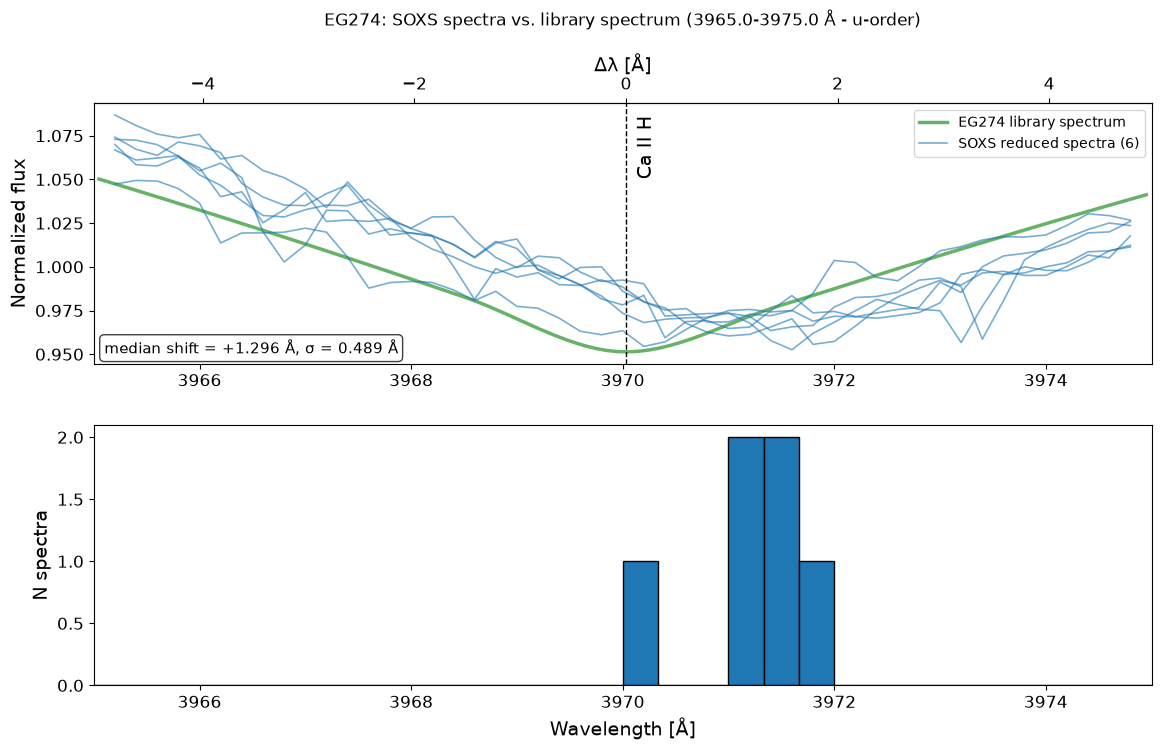

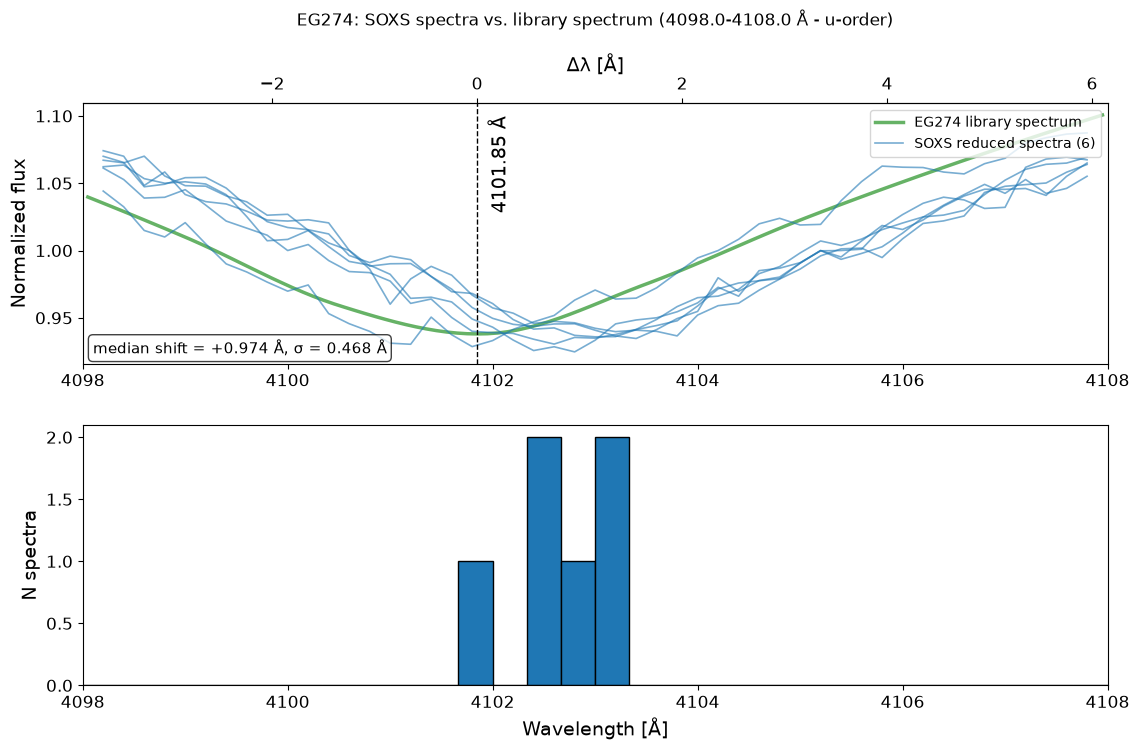

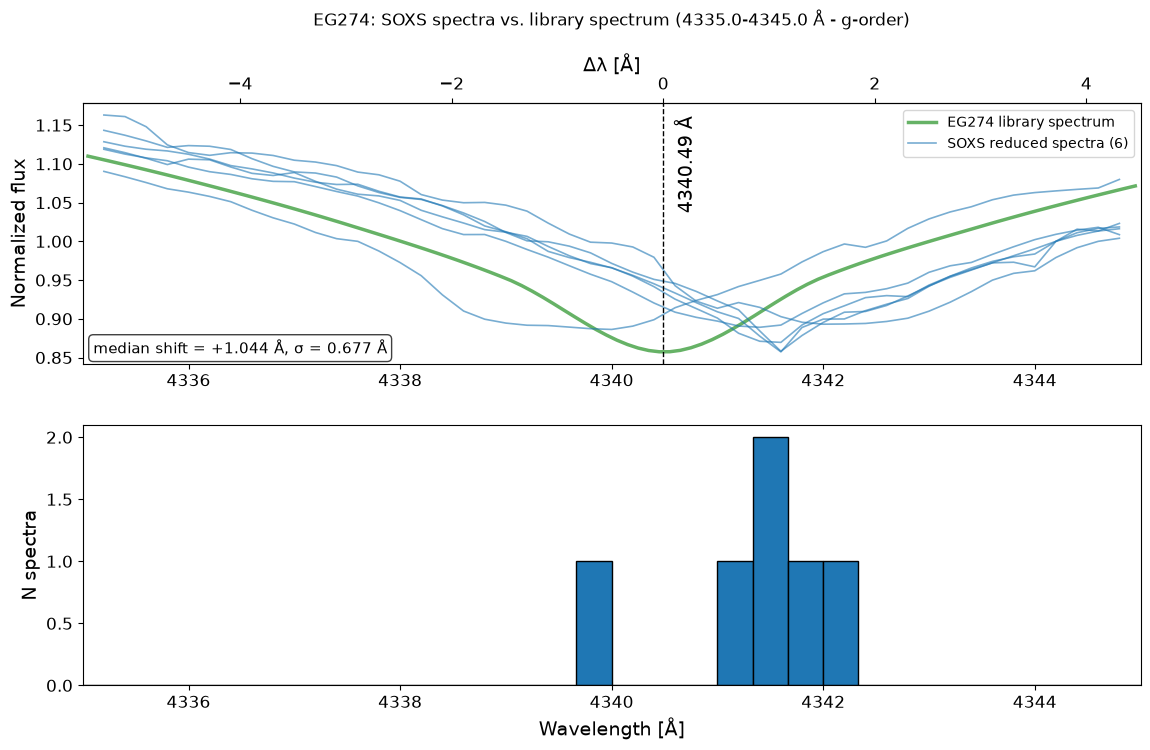

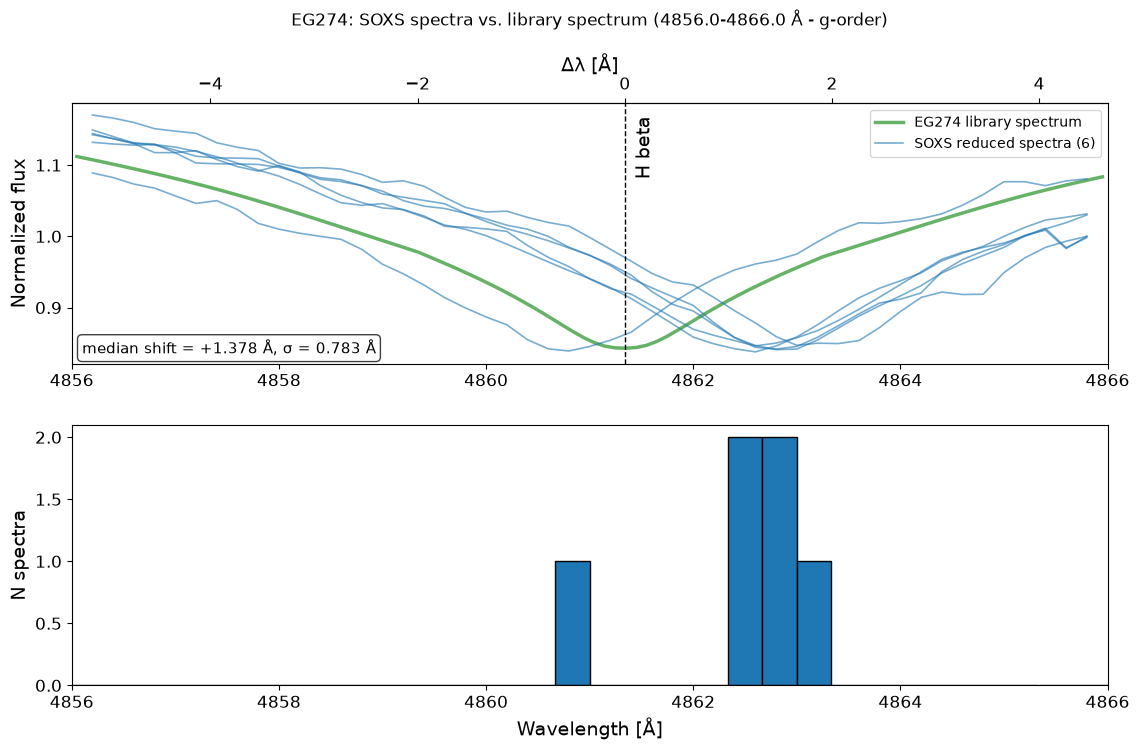

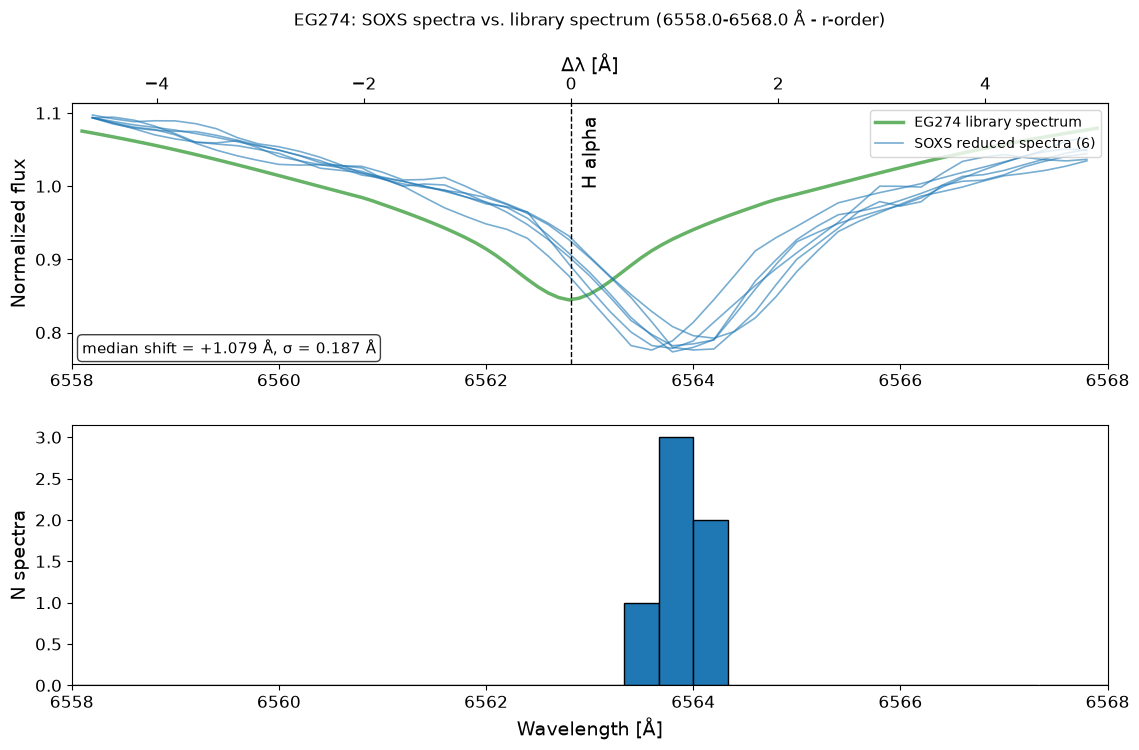

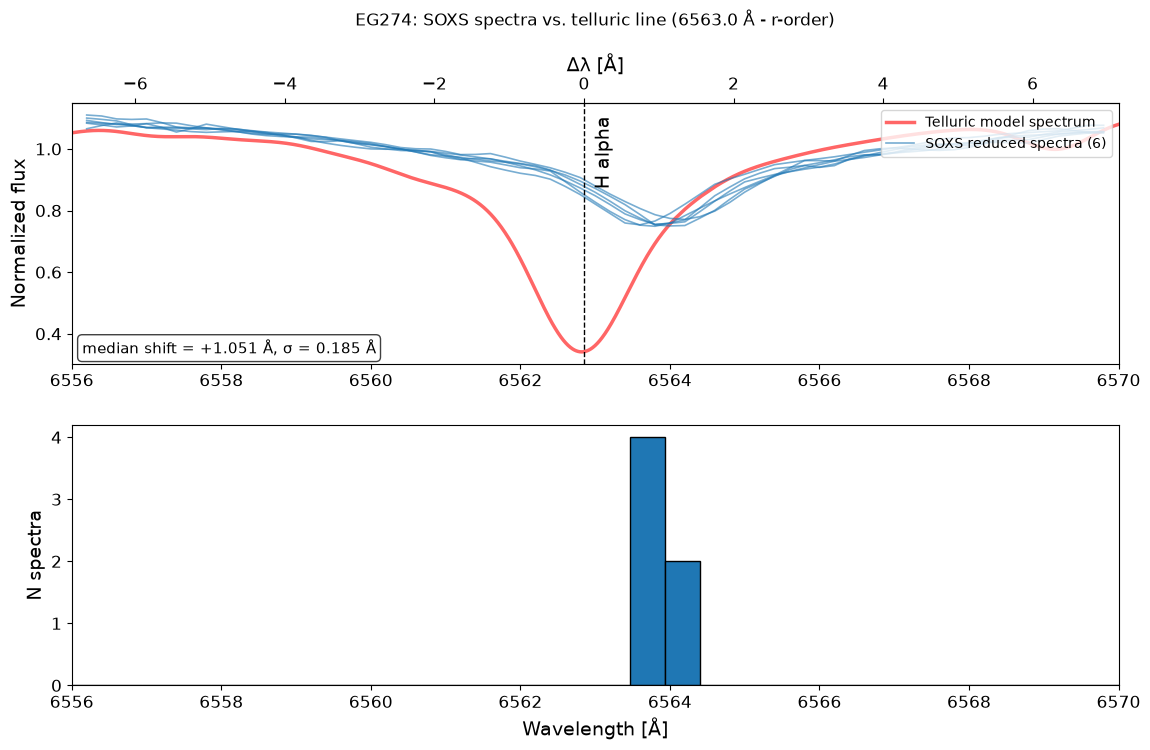

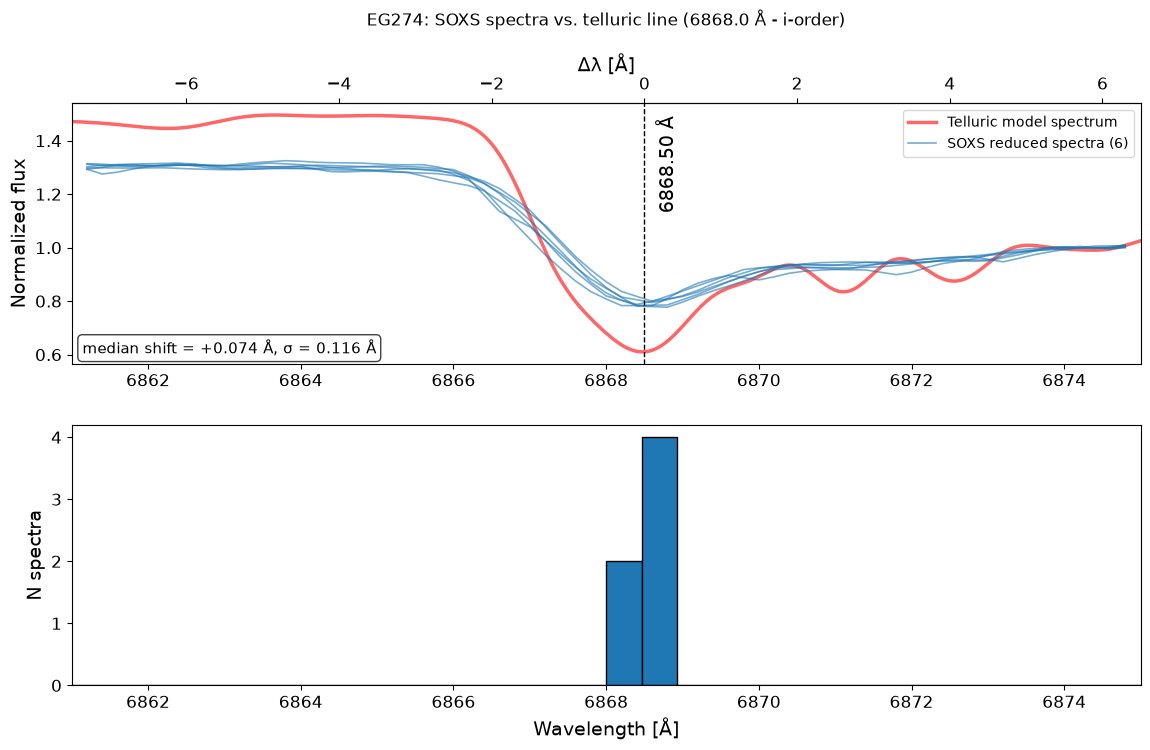

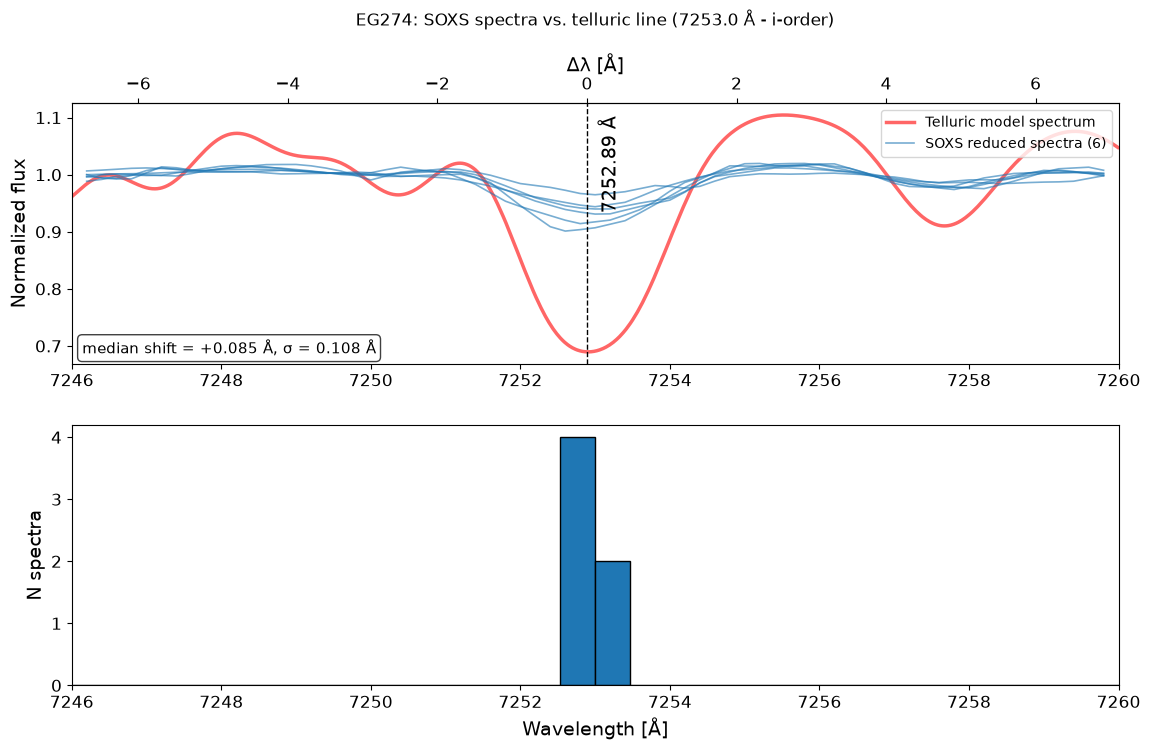

## LTT7987

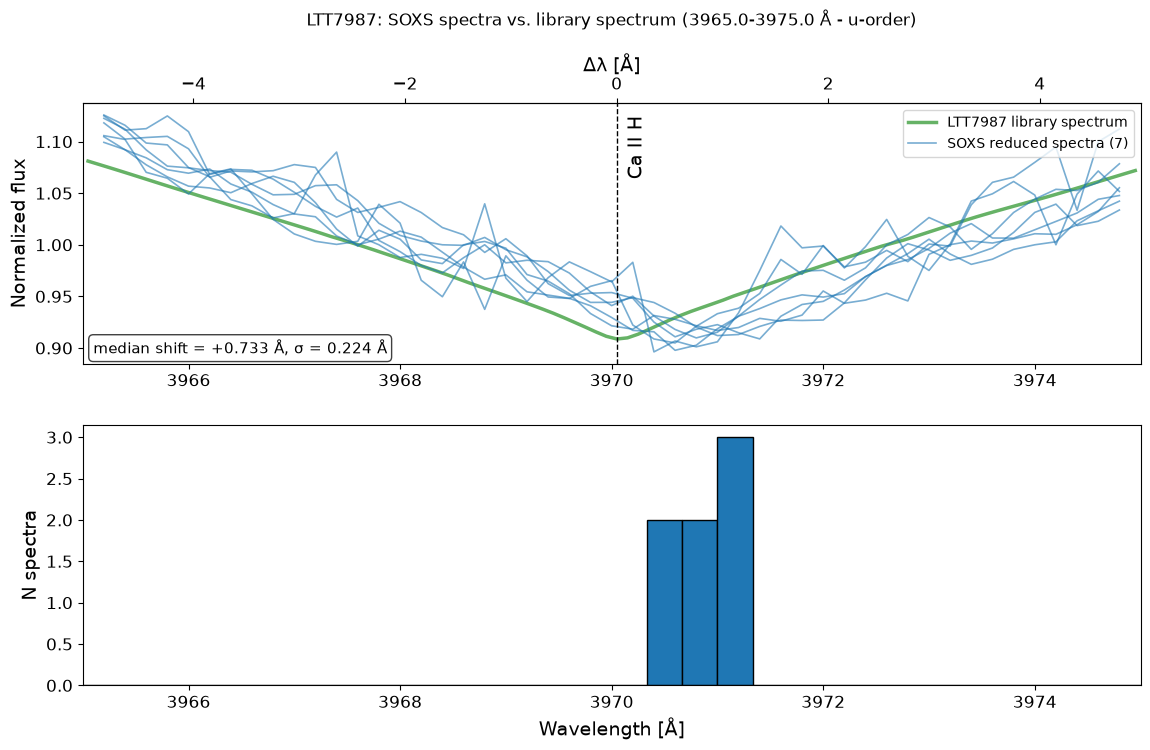

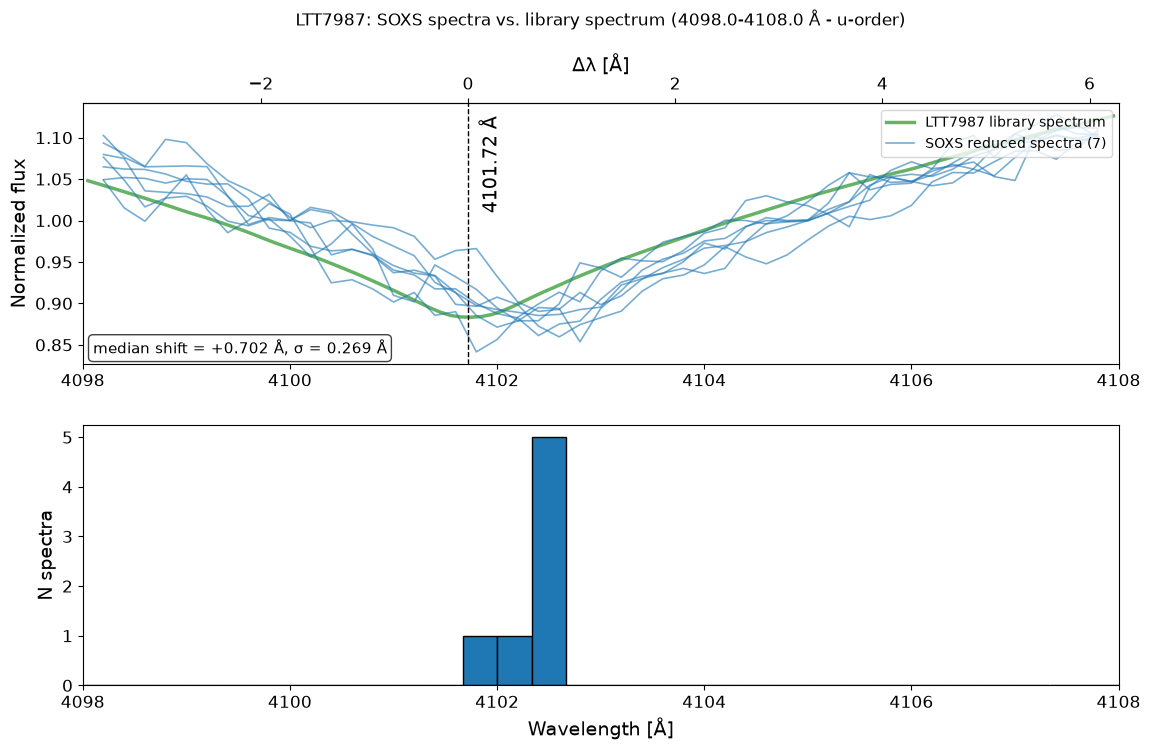

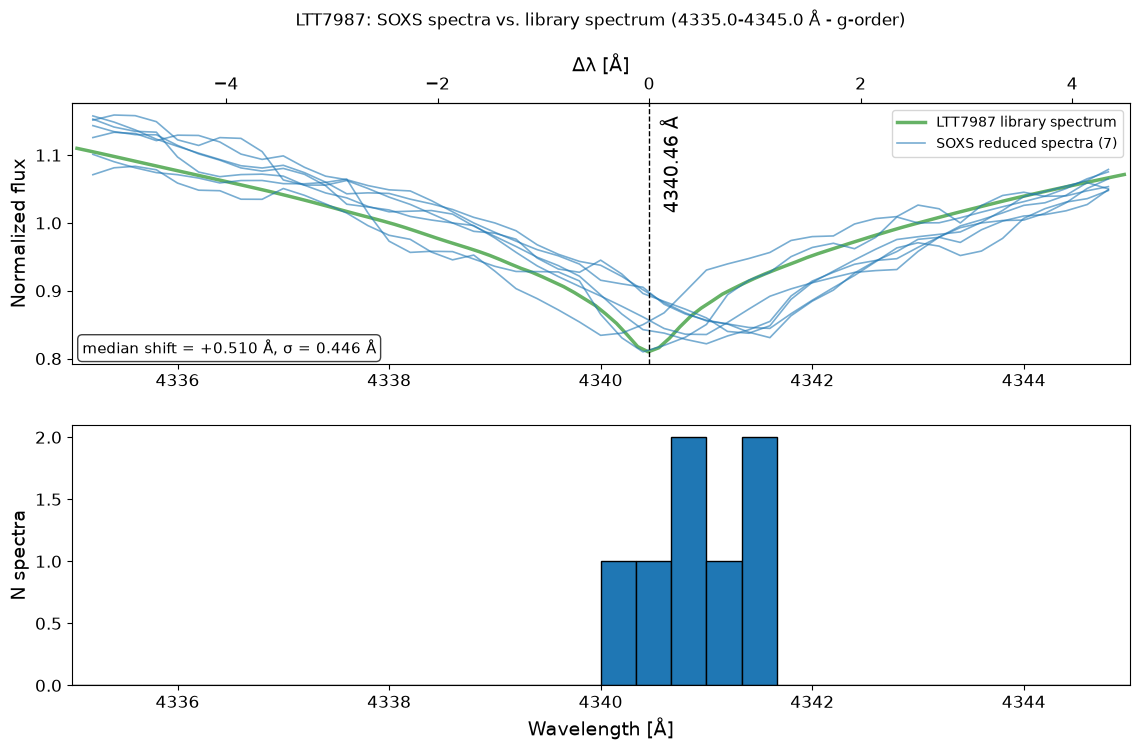

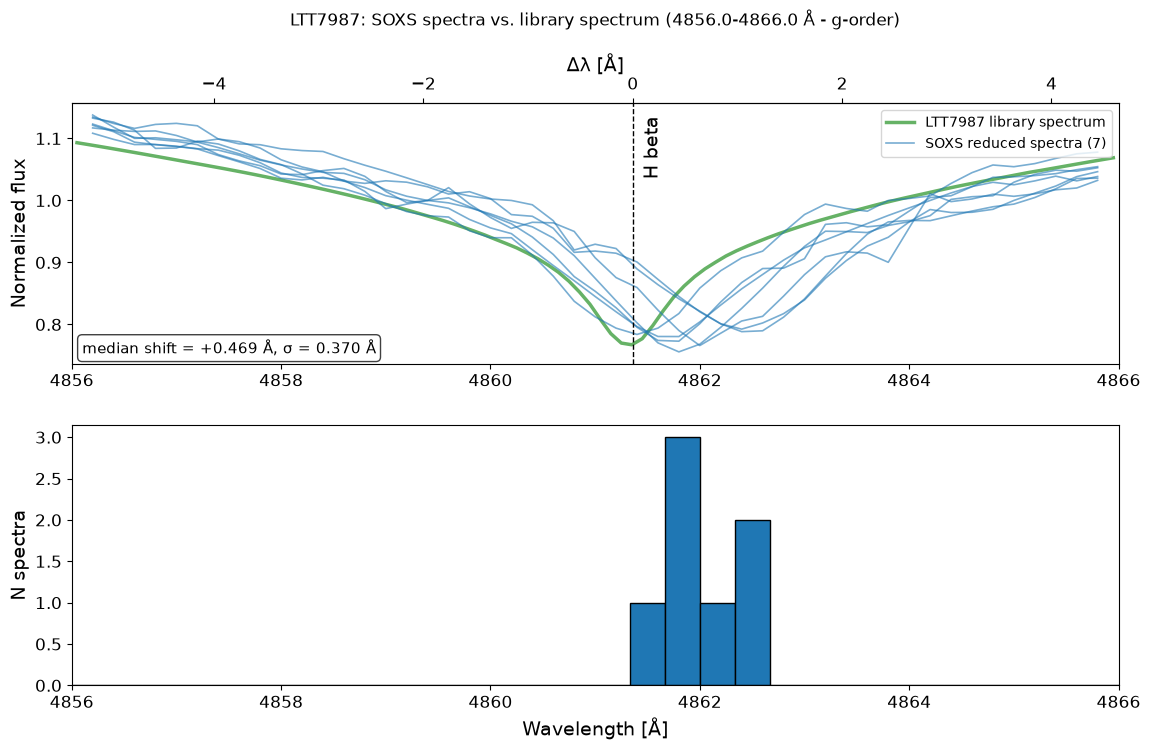

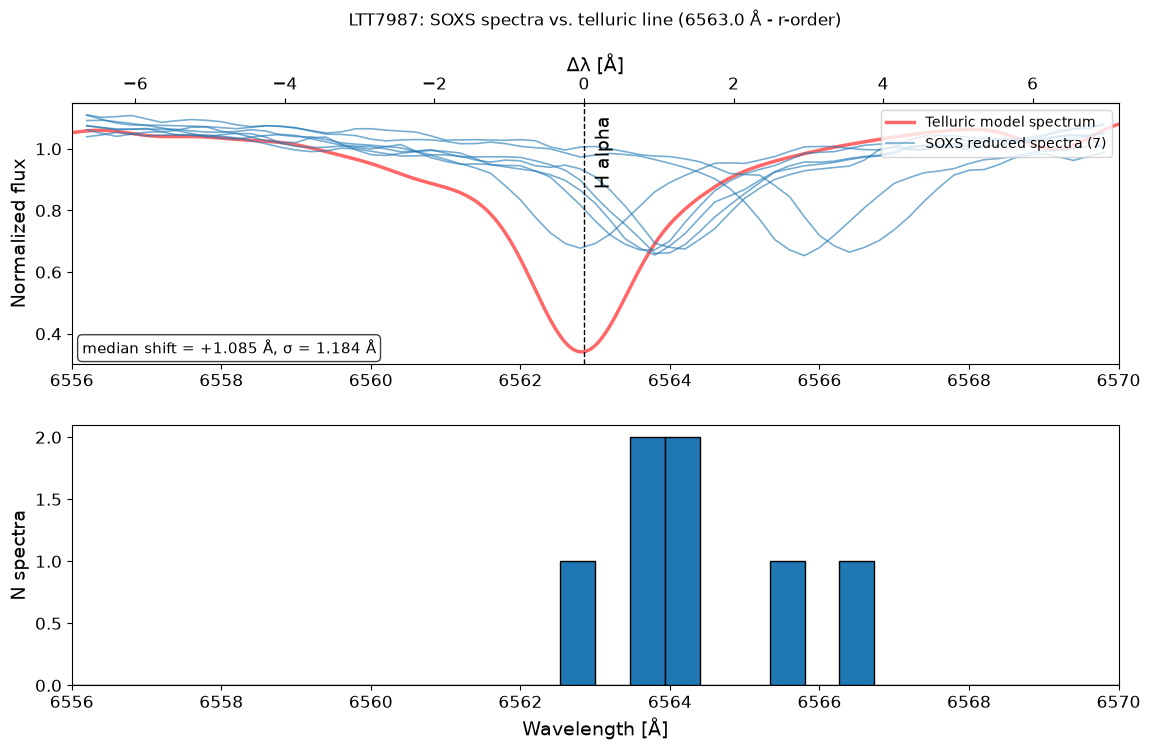

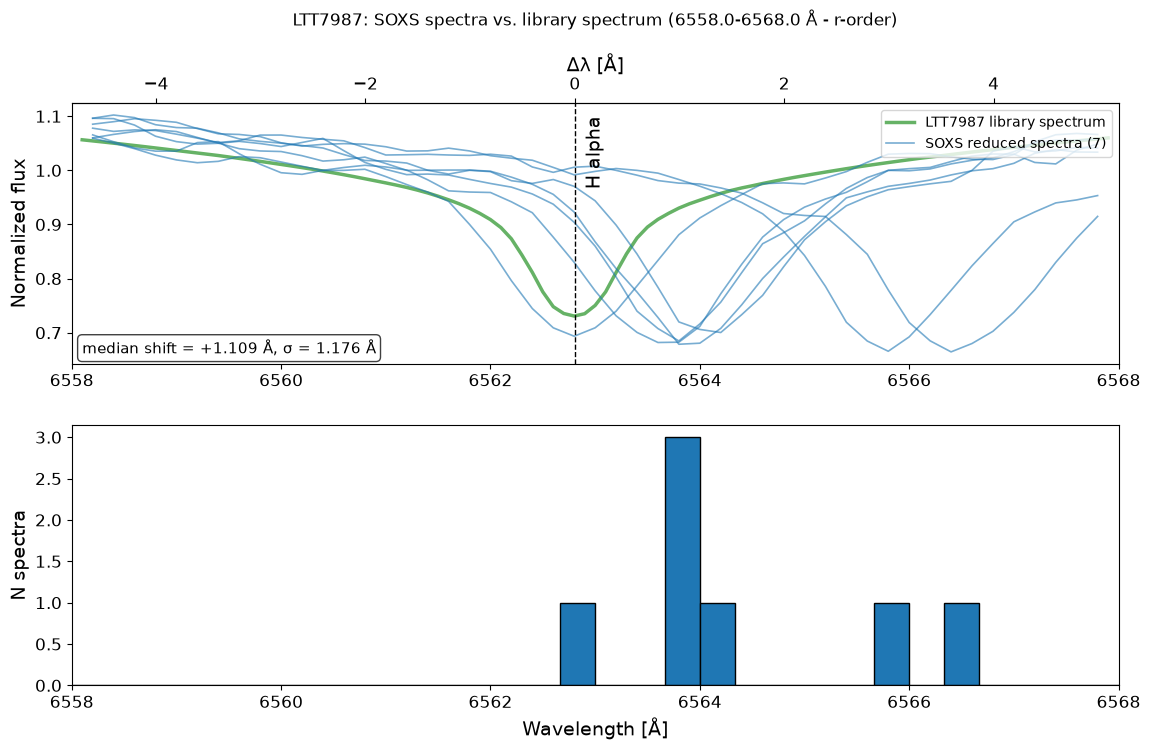

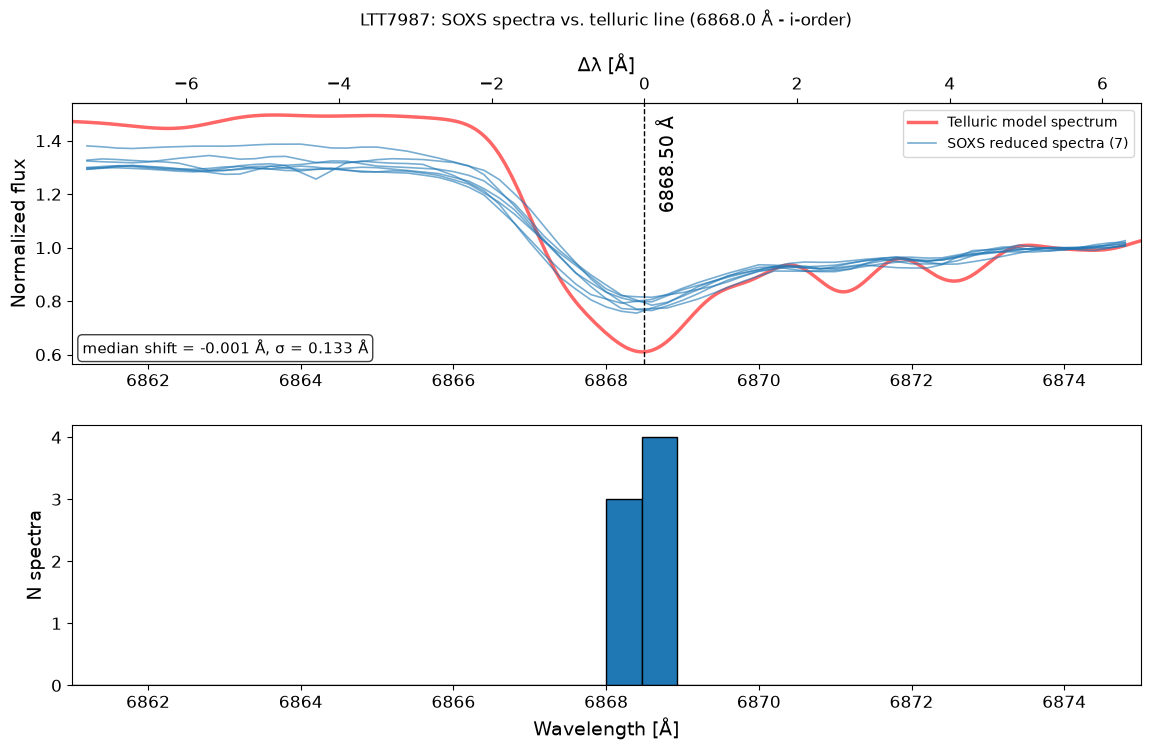

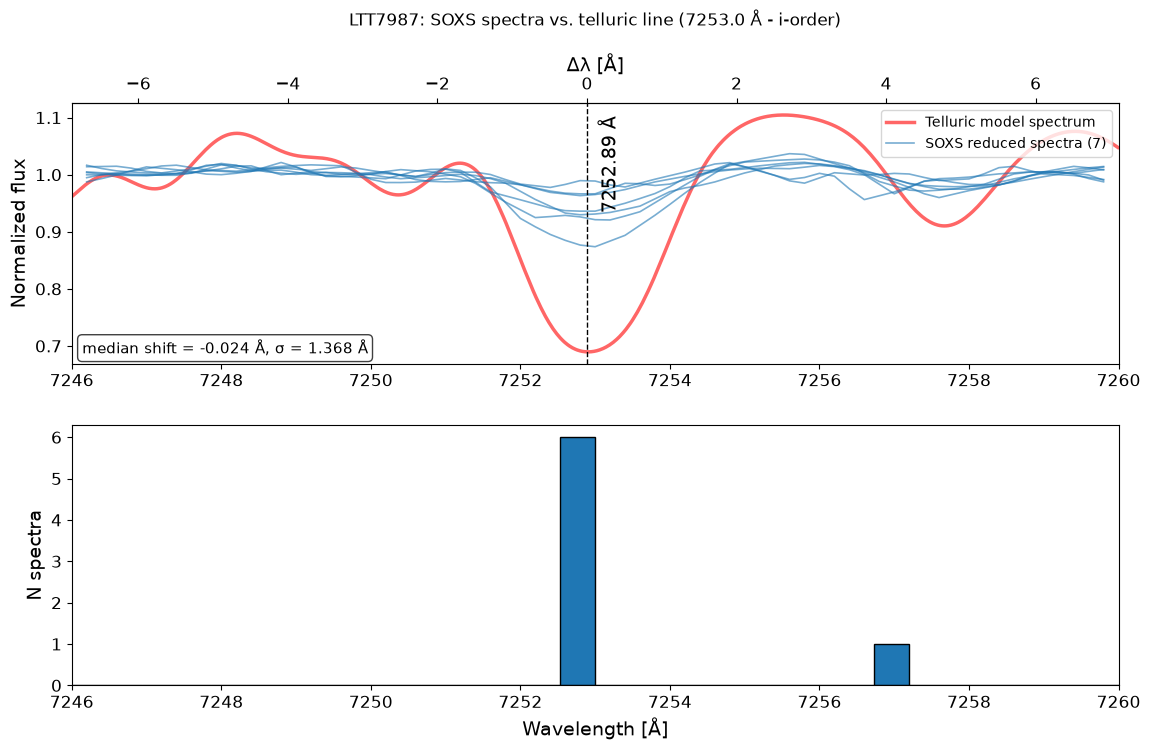

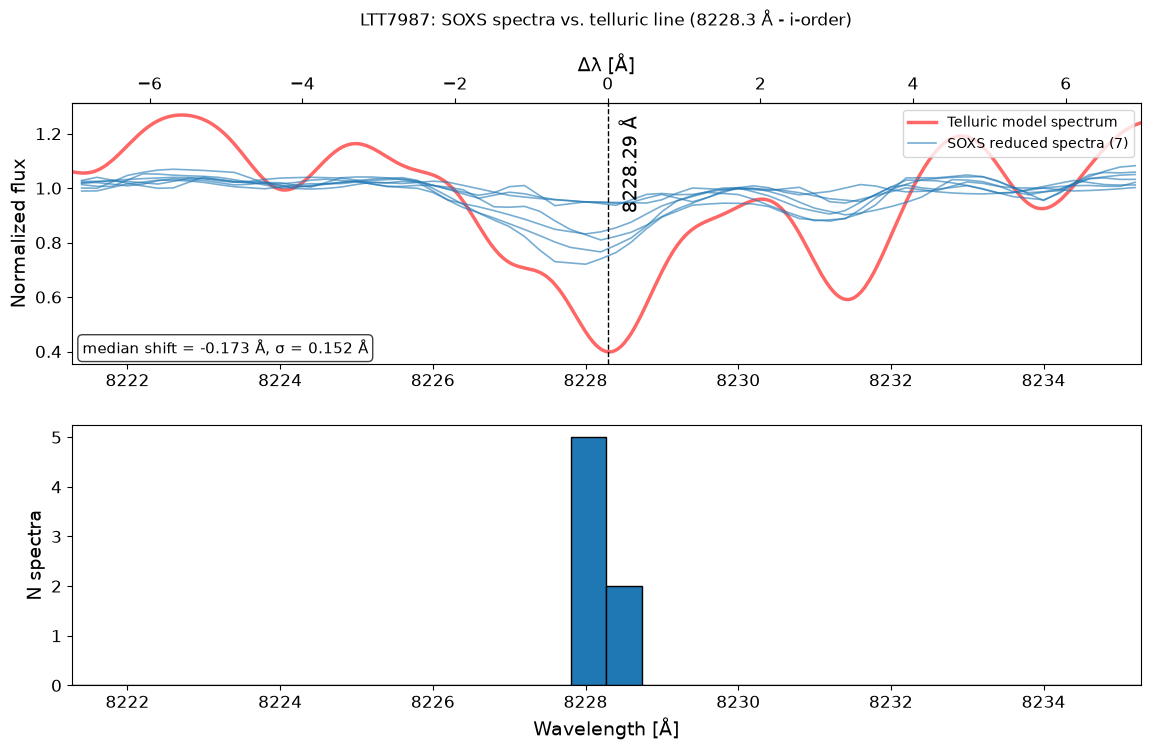

## Feige110

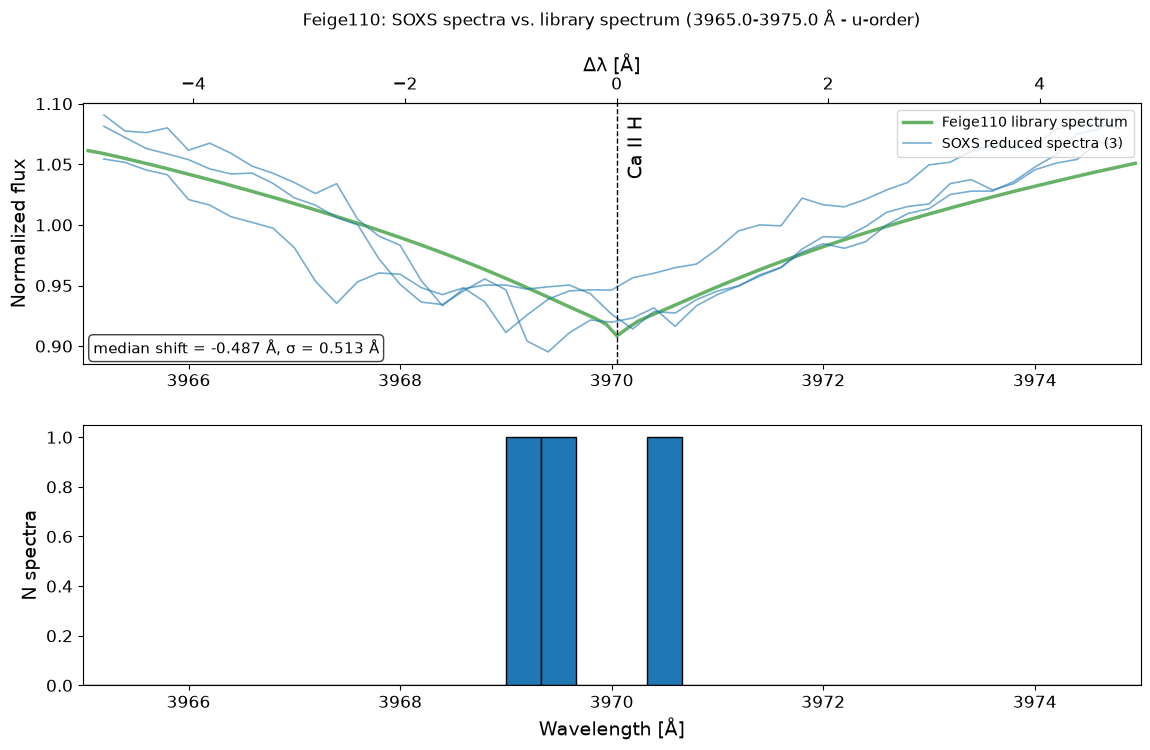

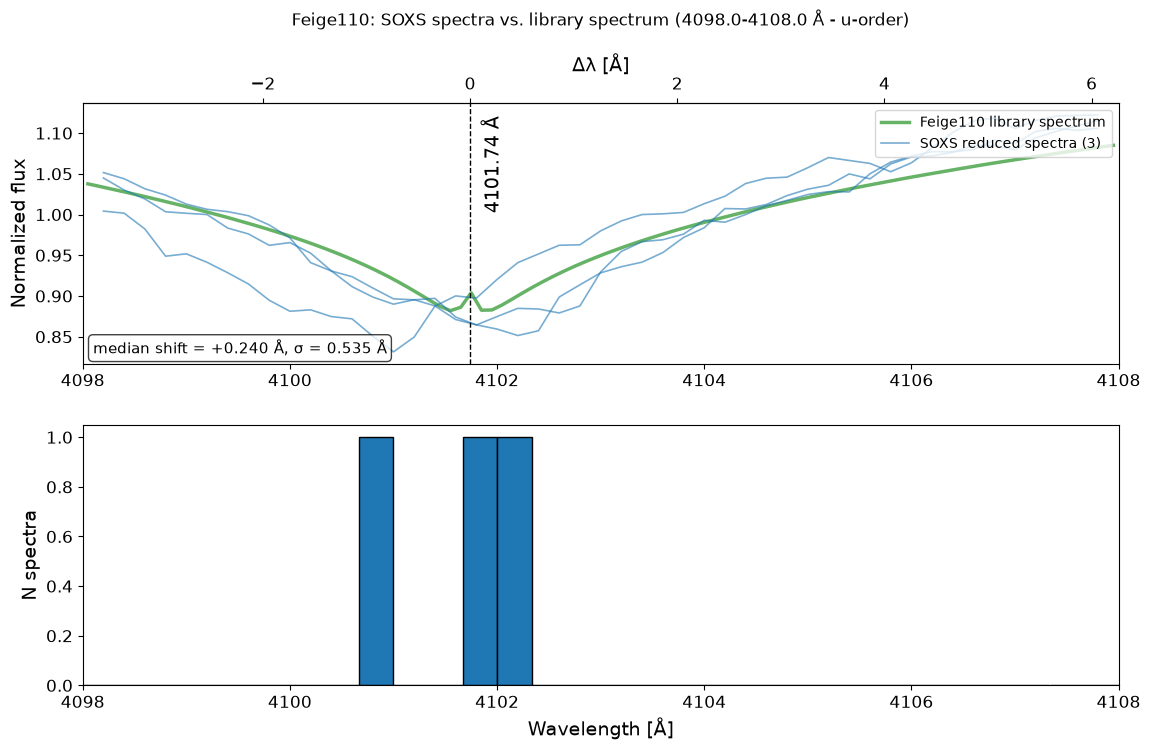

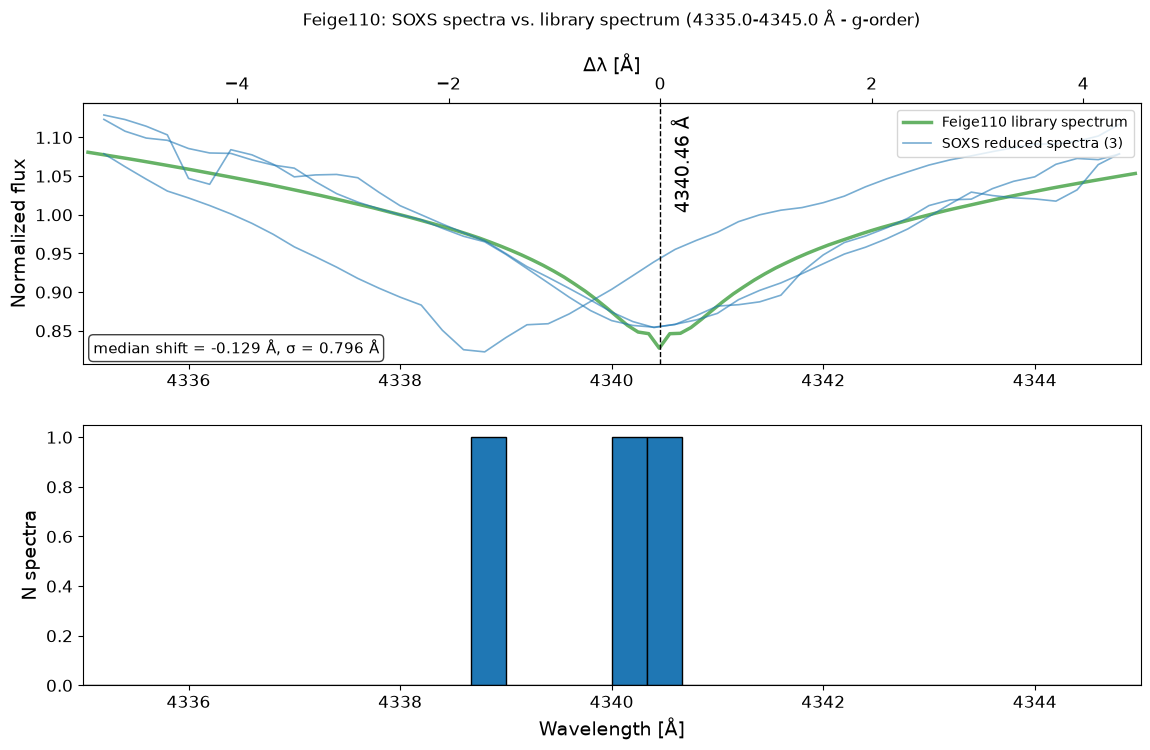

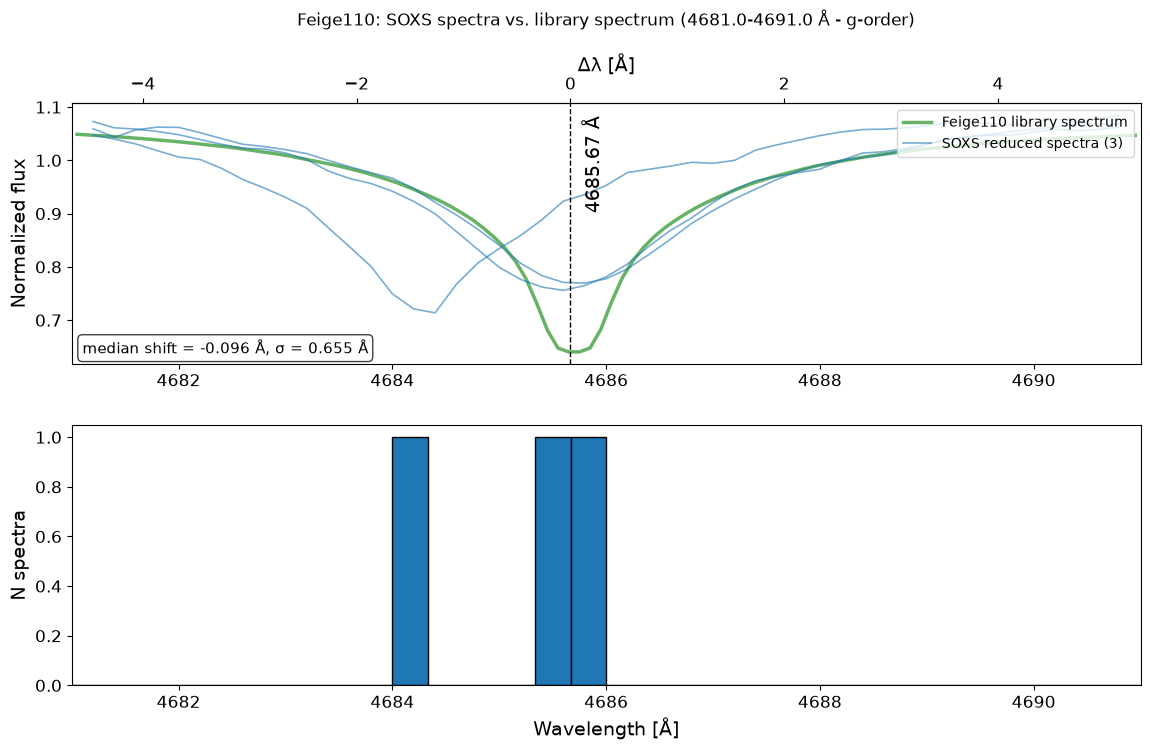

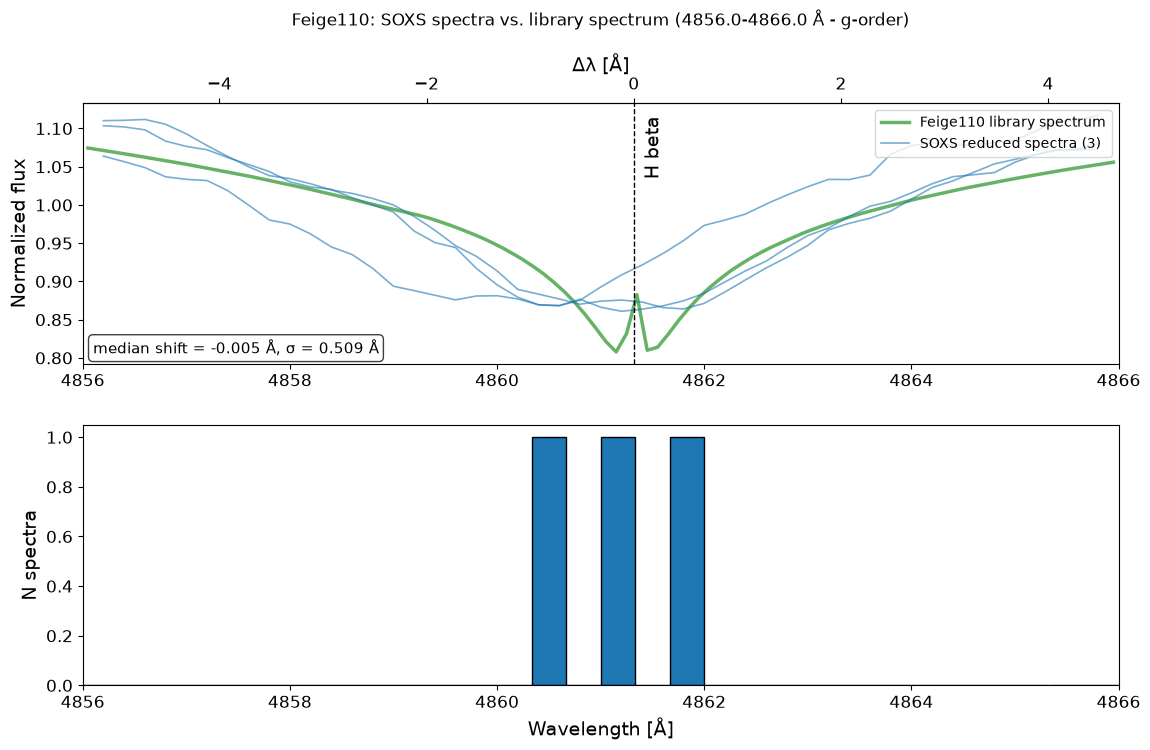

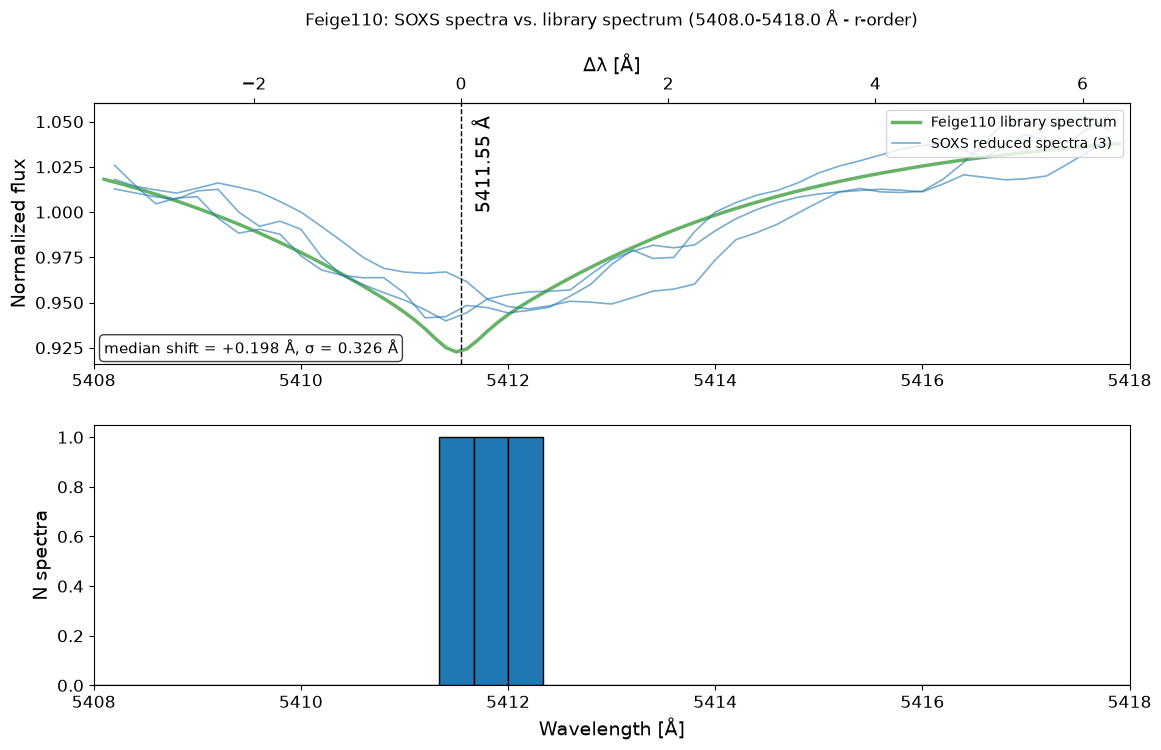

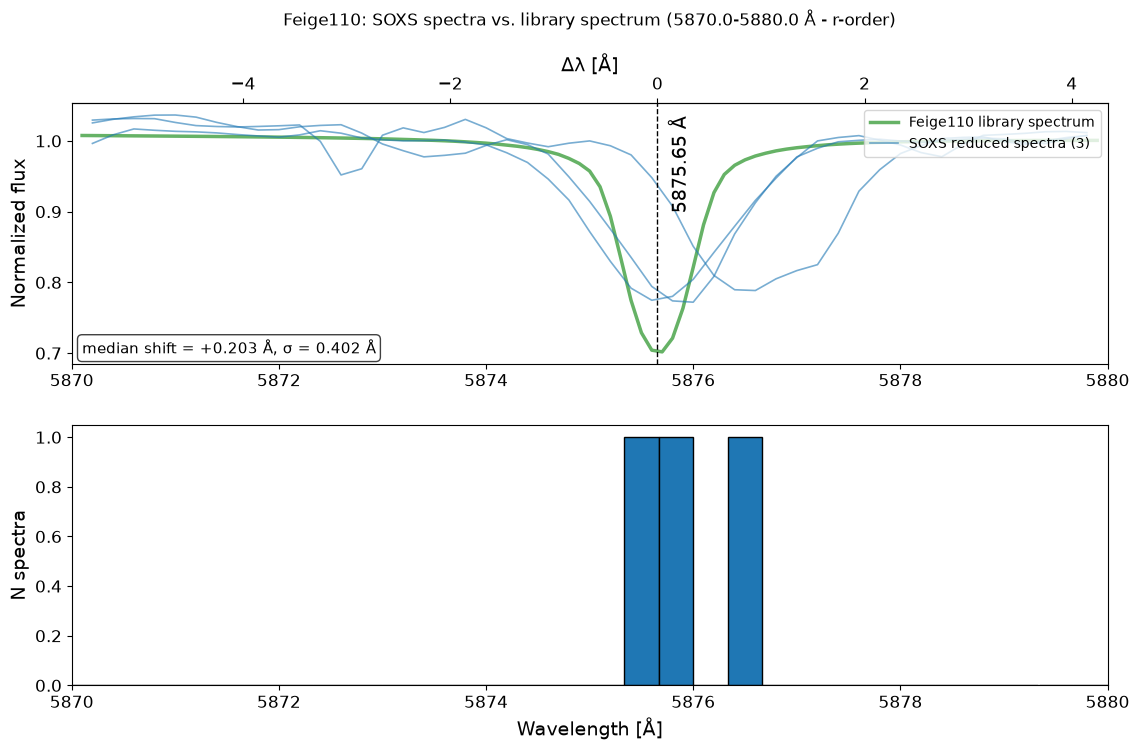

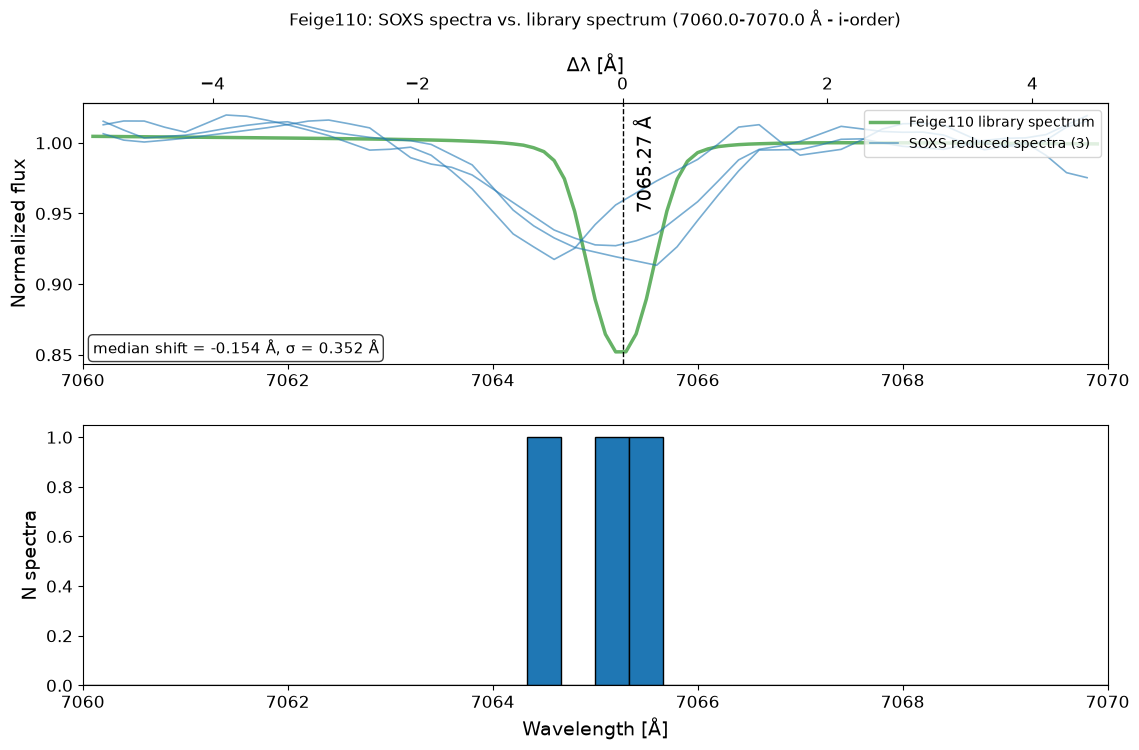

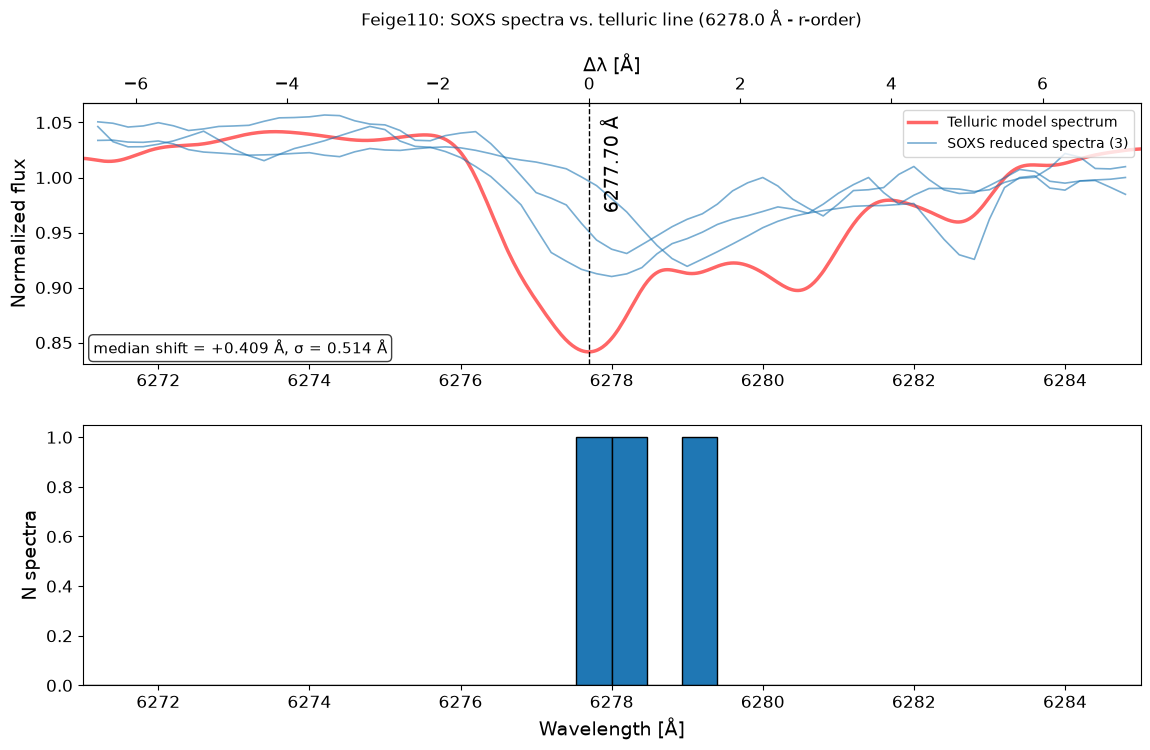

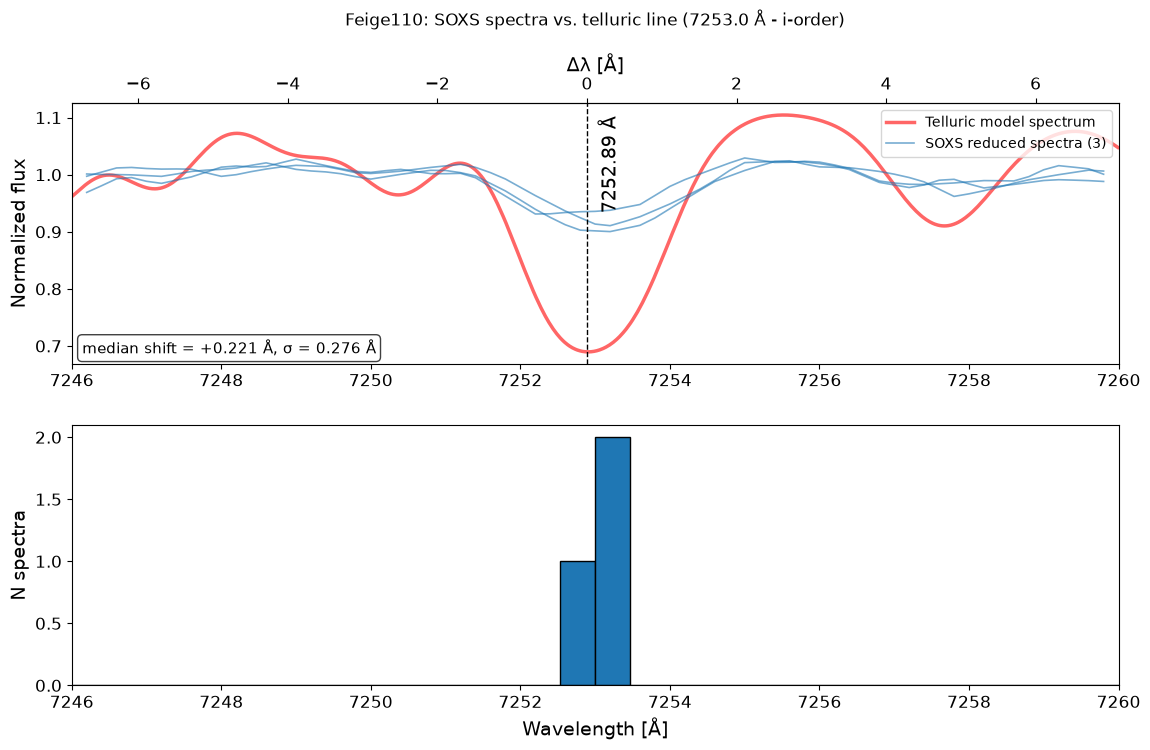

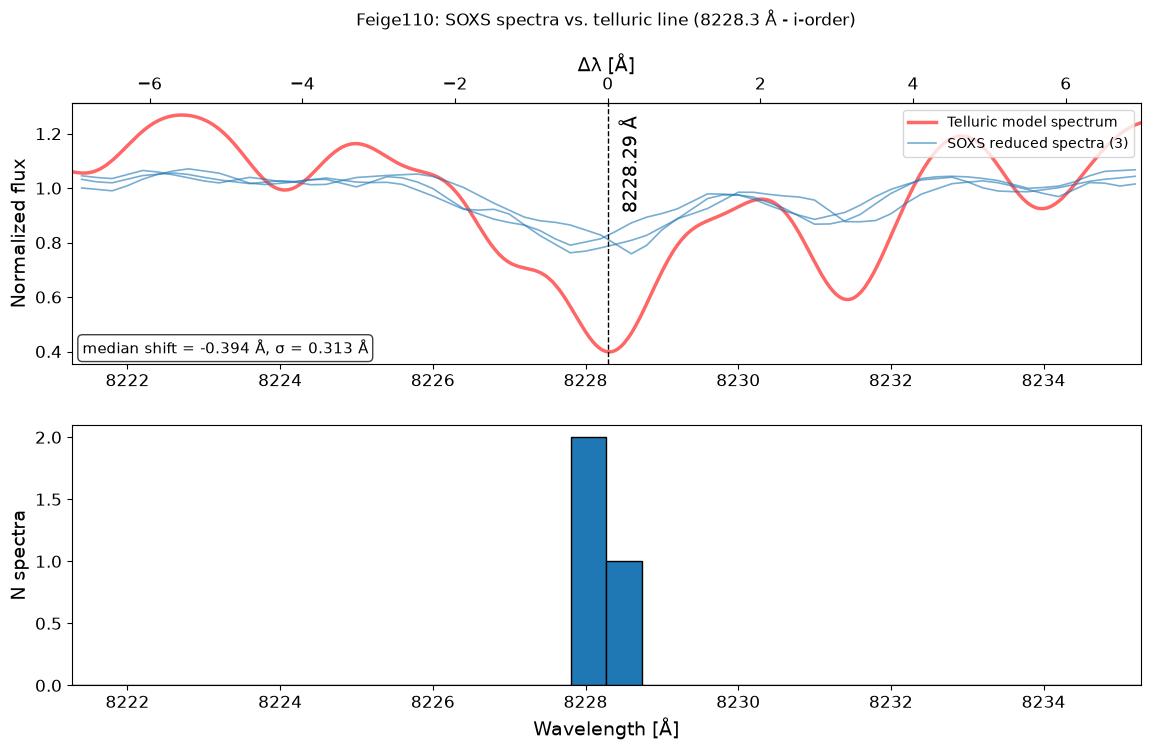

## EG21

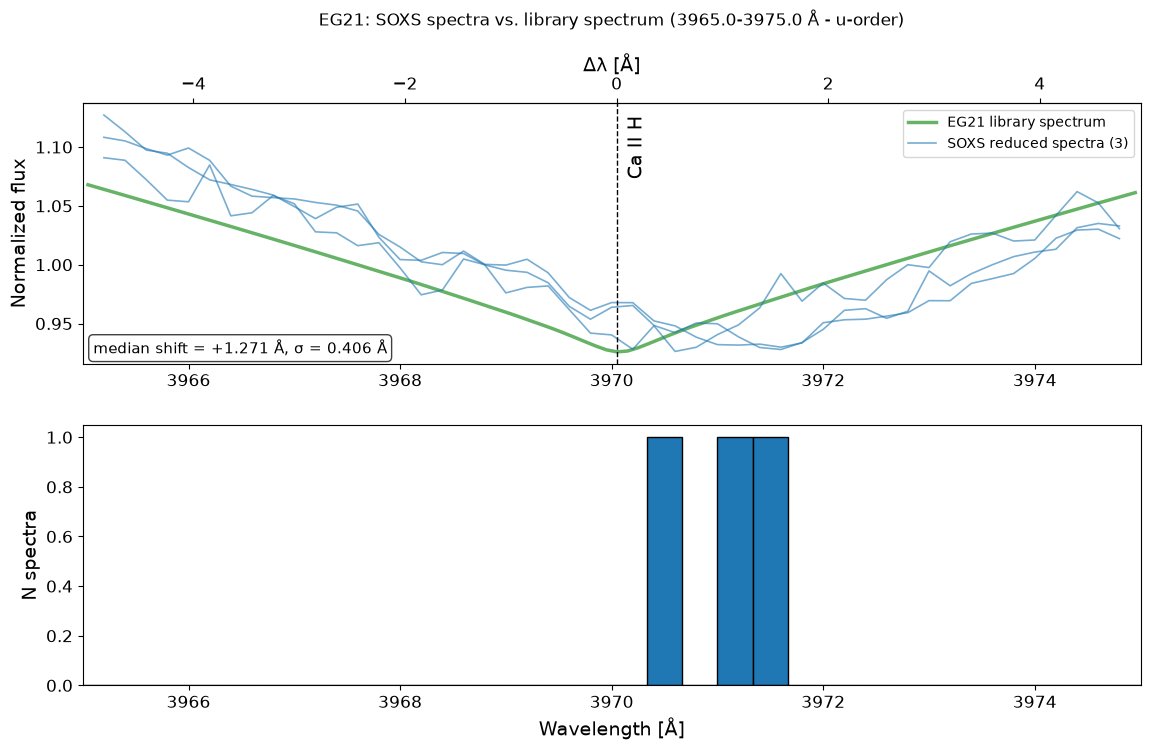

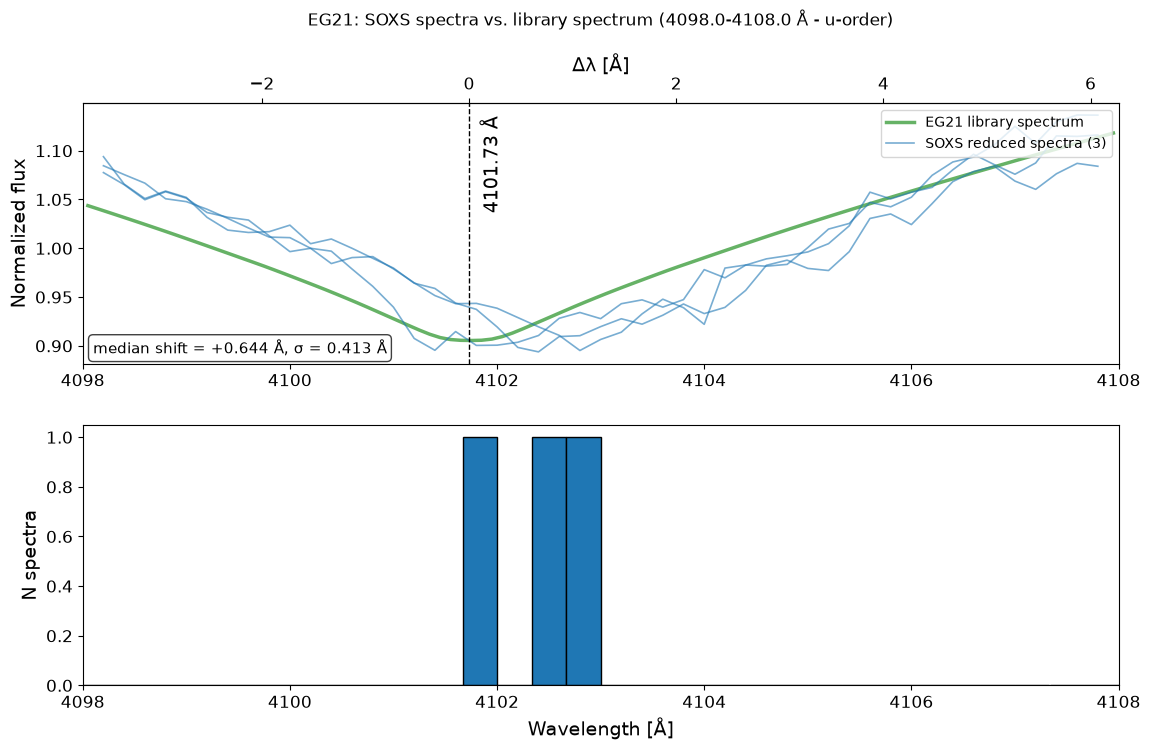

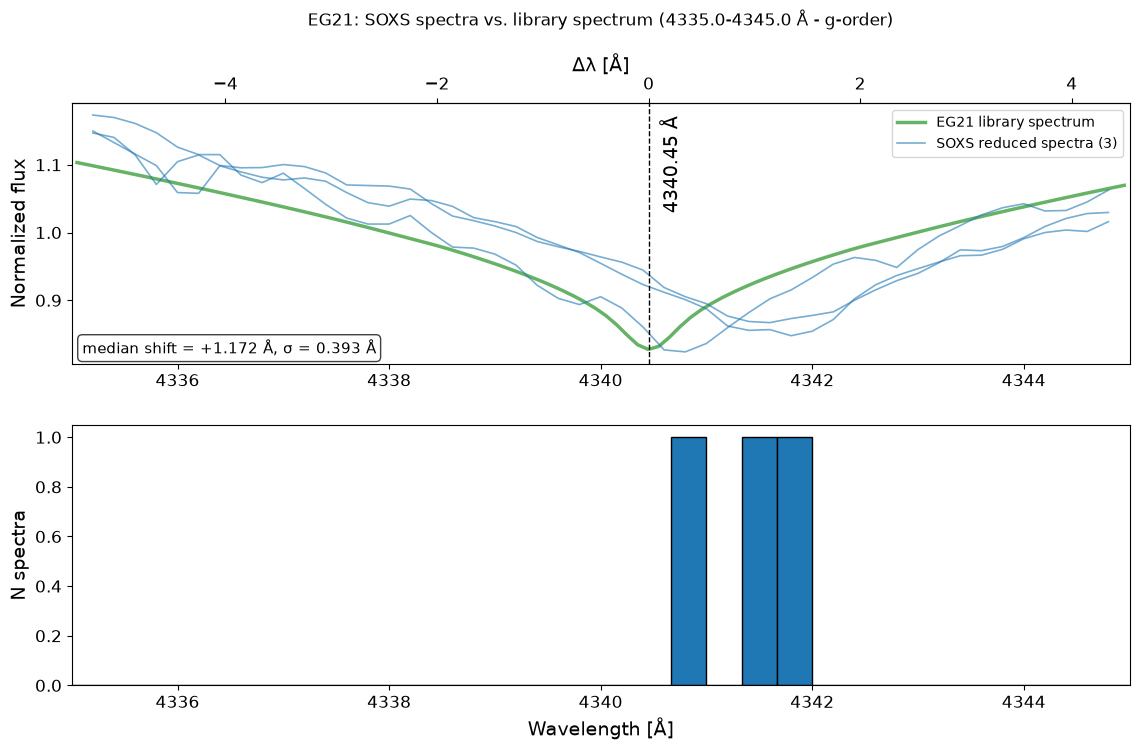

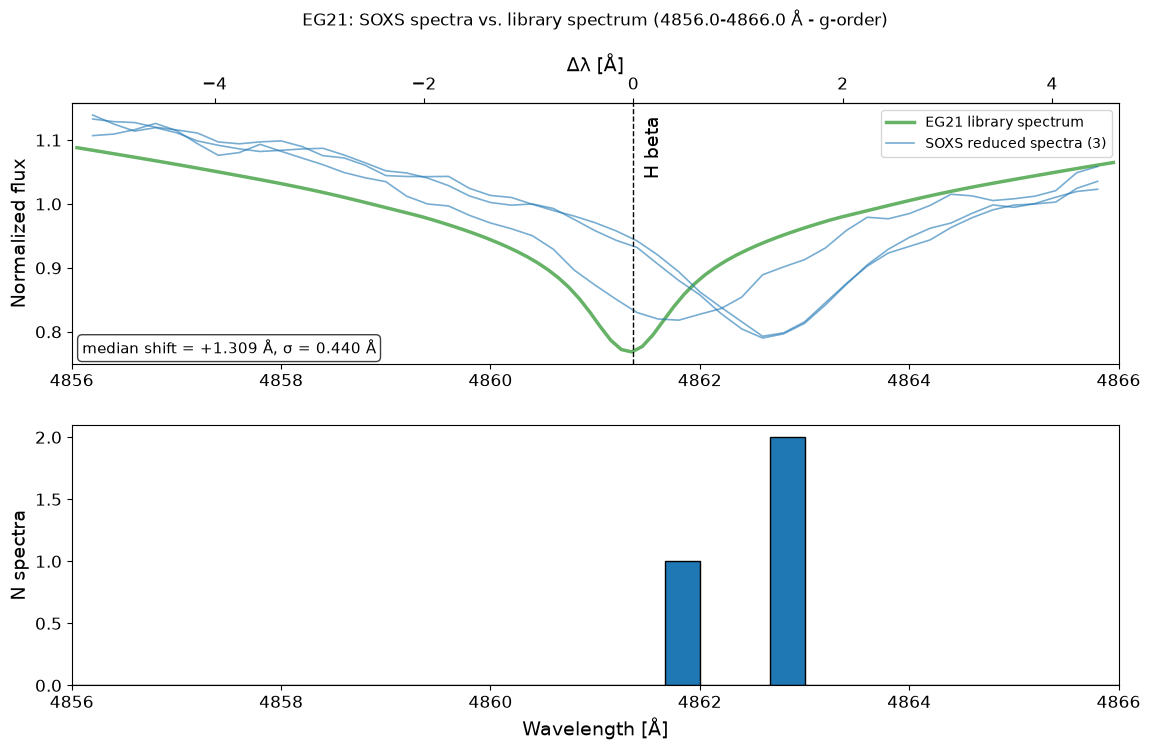

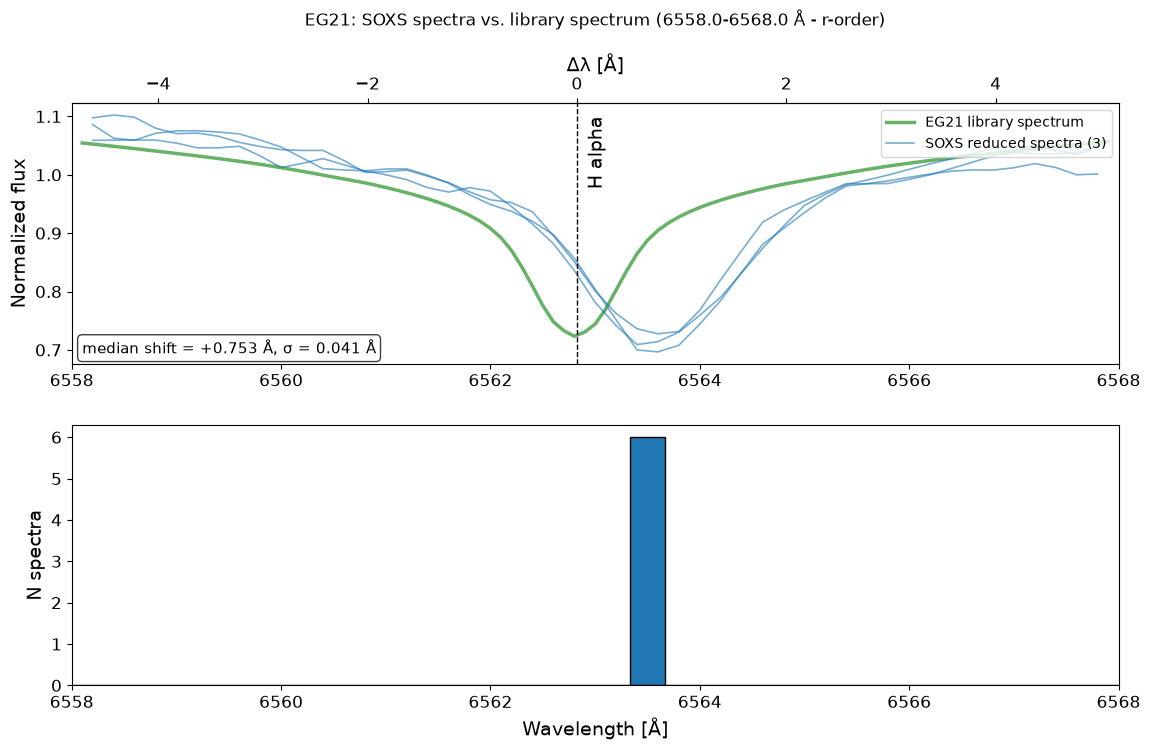

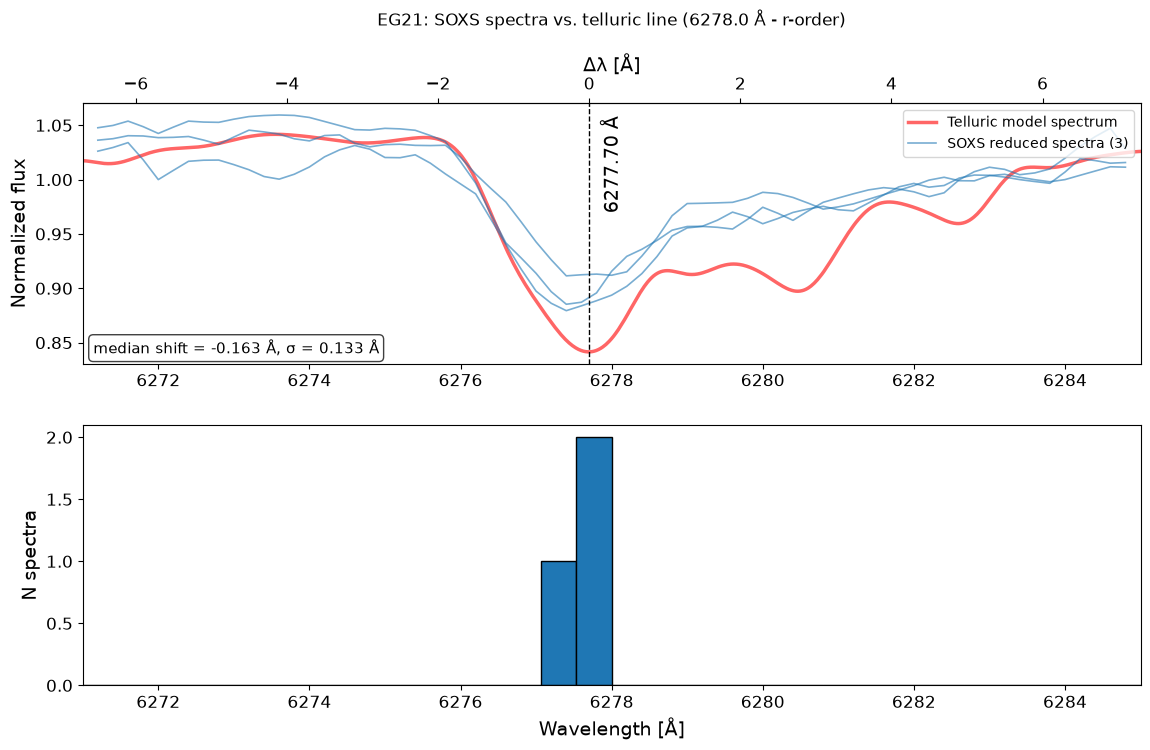

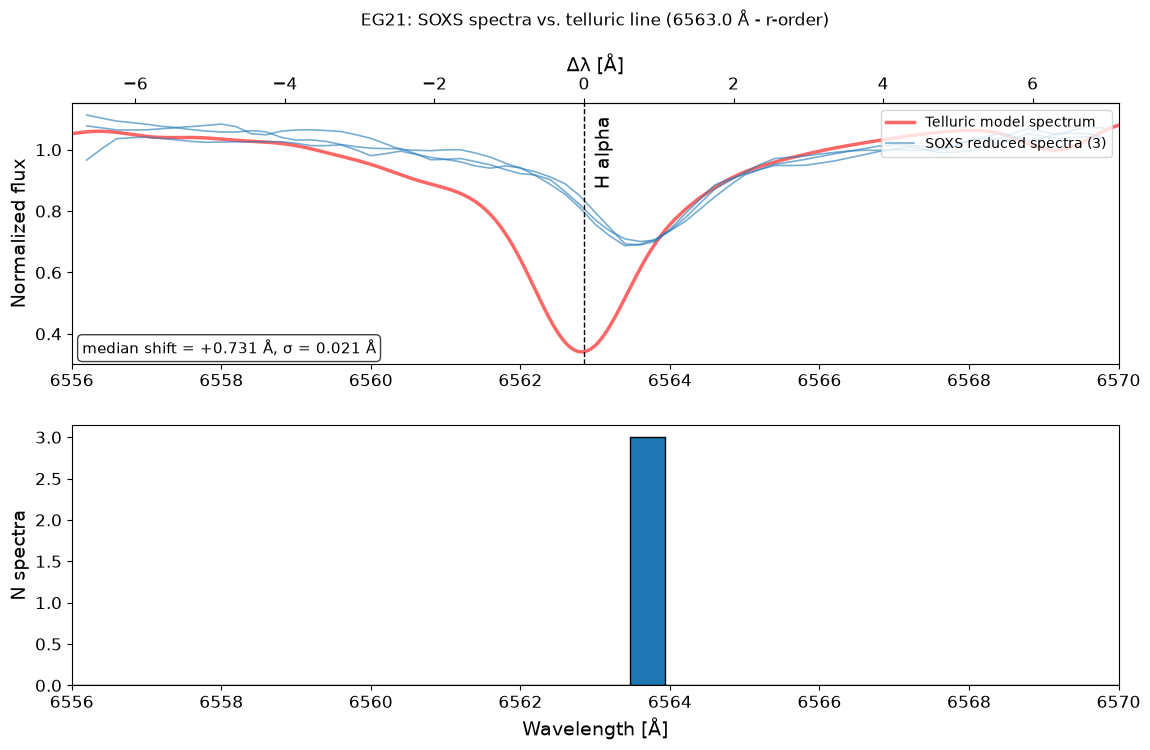

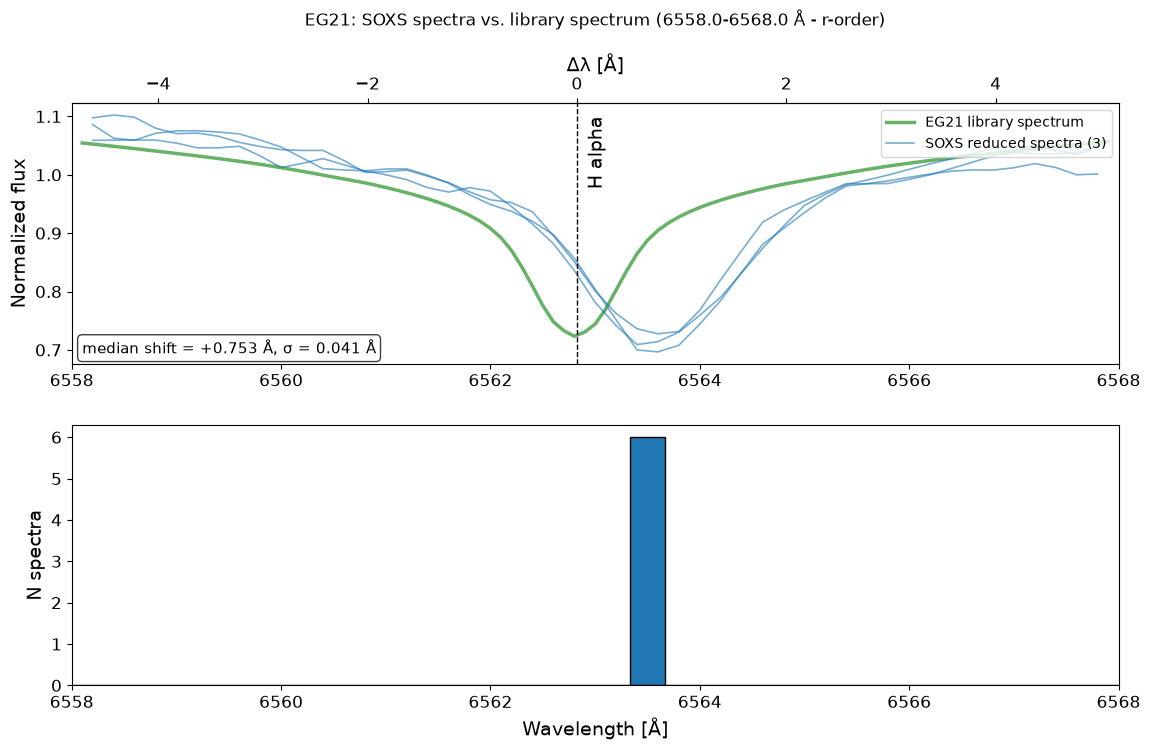

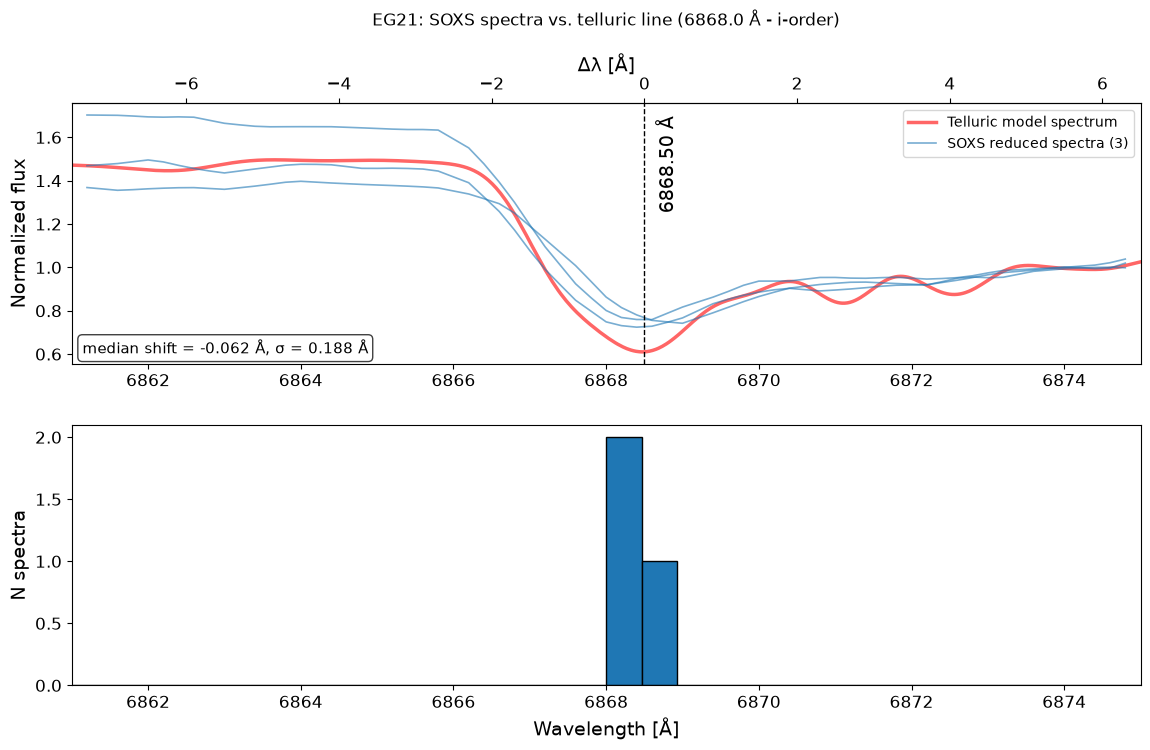

In [83]:
# PLOT: STAR/WINDOW COMPARISON (+ OPTIONAL METRICS) PLOTS FOR EVERY (STAR, WINDOW) COMBINATION
# (REUSES THE MEASUREMENTS FROM resultsDf ABOVE -- NO RE-FITTING)
for starName, windowsForStar in STANDARD_STARS.items():    
    matchedSpectra, matchedDetails = get_spectra_for_star(standardsData, details, starName)

    if len(matchedSpectra) == 0:
        continue

    display(Markdown(f"## {starName}"))

    for windowMin, windowMax in windowsForStar:

        order = assign_spectral_order(windowMin, windowMax, spectralFormatDf)

        if ORDERS_TO_INSPECT is not None and order not in ORDERS_TO_INSPECT:
            continue

        if windowMin < windowMax:
            windowTag = f"{starName}_{windowMin:.0f}-{windowMax:.0f}A"
        else:
            windowTag = f"{starName}_telluric_line_{windowMax:.0f}A"

        if windowMin == windowMax:
            telluric = windowMin
            # WIDEN BY THE SAME +/-7 A AS measure_shifts_for_window SO THIS WINDOW MATCHES THE
            # WindowMinAngstrom/WindowMaxAngstrom RECORDED IN resultsDf BELOW.
            windowMin -= 7.
            windowMax += 7.
            # TELLURIC LINE WINDOW -- USE THE TELLURIC MODEL SPECTRUM AS THE REFERENCE
            libraryWaveNmArg, libraryFluxArg = telluricSpectrumWaveAngstrom / 10.0, telluricSpectrumFlux
        else:
            telluric = False
            libraryWaveNmArg, libraryFluxArg = data['WAVE'], data[starName]

        resultsForWindow = resultsDf[
            (resultsDf['Star'] == starName) &
            (resultsDf['WindowMinAngstrom'] == windowMin) &
            (resultsDf['WindowMaxAngstrom'] == windowMax)
        ].to_dict('records')

        plot_comparison(
            starName, windowMin, windowMax,
            matchedSpectra, matchedDetails,
            libraryWaveNmArg, libraryFluxArg,
            resultsForWindow,
            order,
            telluric=telluric,
            savePath=f"{PLOTS_DIR}{windowTag}_comparison.png",
        )
        if PLOT_METRICS:
            plot_metrics(
                starName, windowMin, windowMax, resultsForWindow,
                savePath=f"{PLOTS_DIR}{windowTag}_metrics.png",
            )


<!-- # Telluric sanity-check plots

Plots every folder spectrum (red) within each `TELLURIC_WINDOWS` range, per star. These are
broad atmospheric-absorption bands rather than single stellar lines, so there is no library
comparison or shift measurement here — just a by-eye check that the telluric features line up
consistently across exposures. A bottom histogram still shows each spectrum's GAM-fitted local
minimum within the window, for reference. -->


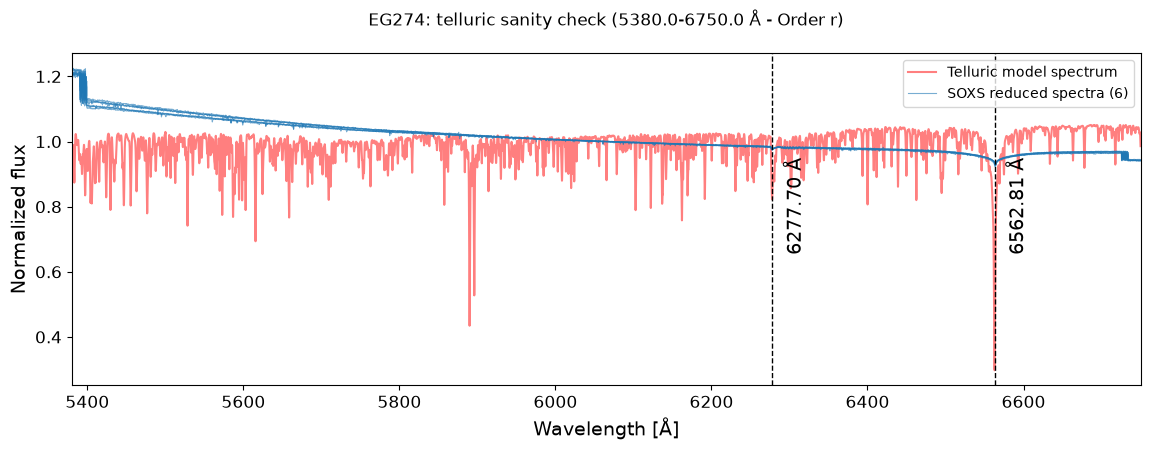

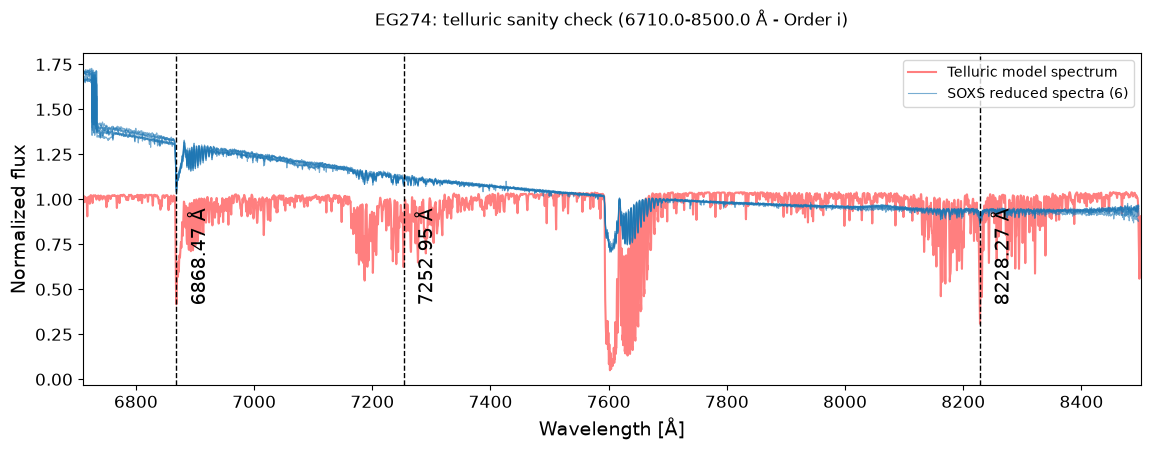

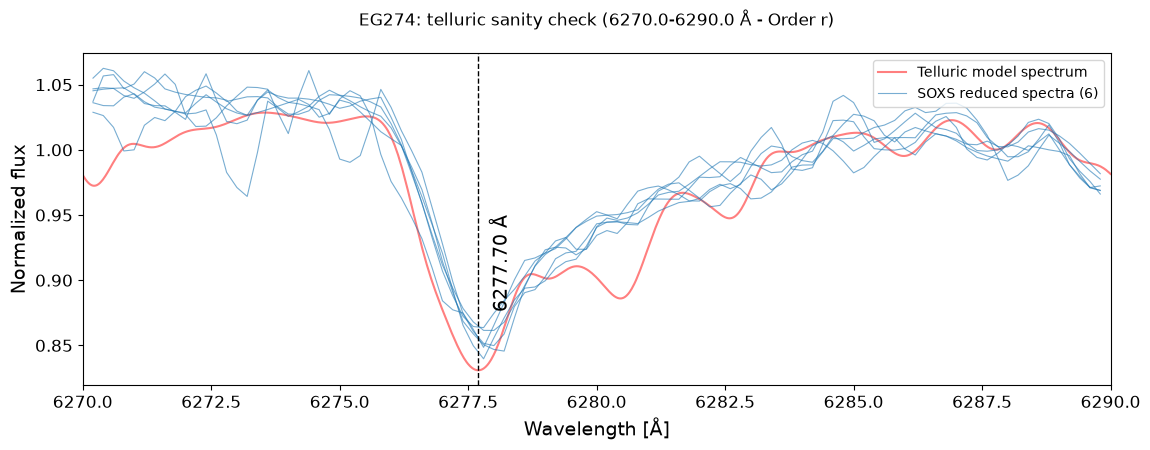

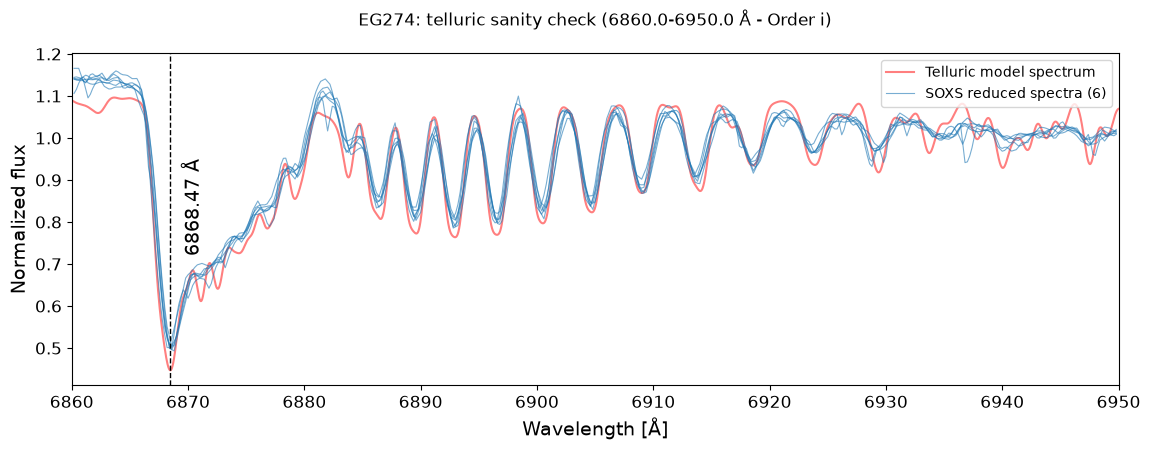

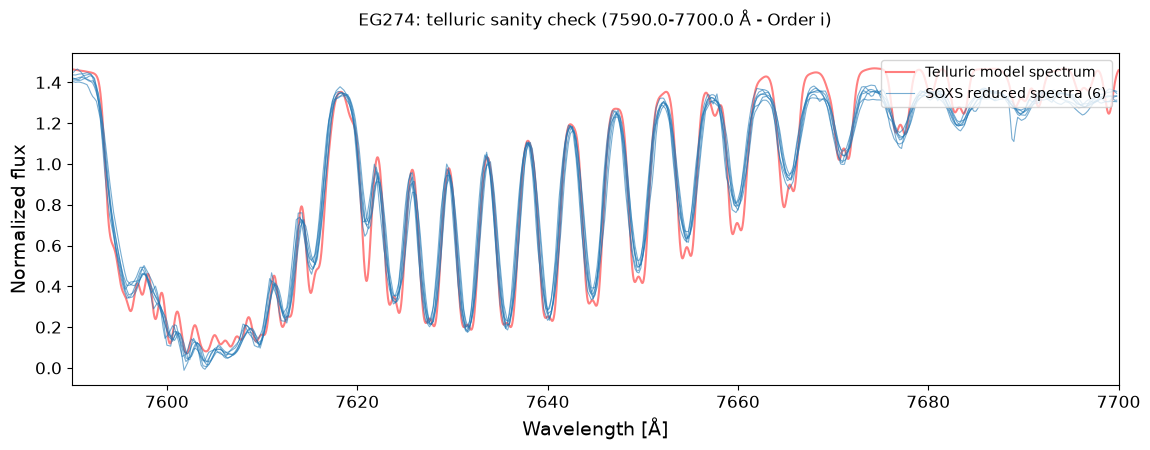

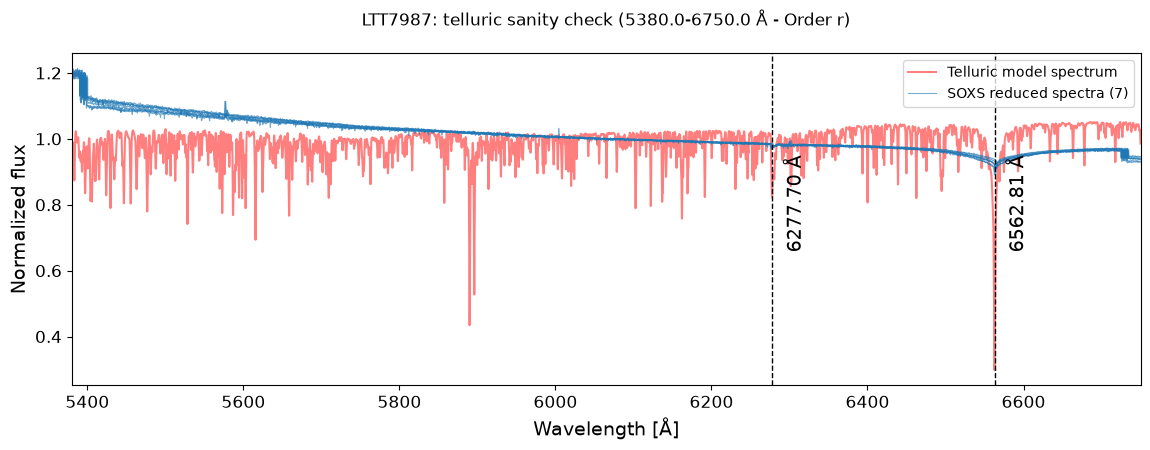

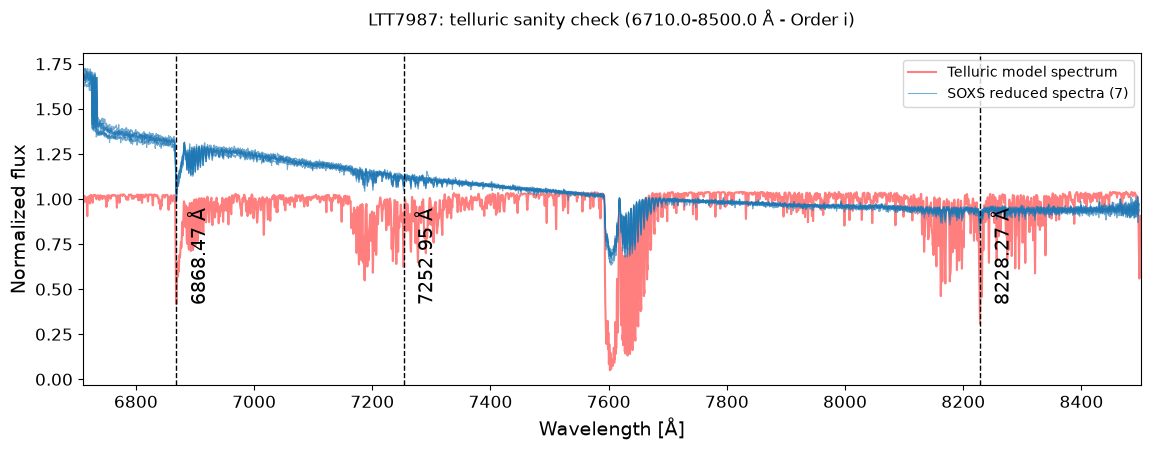

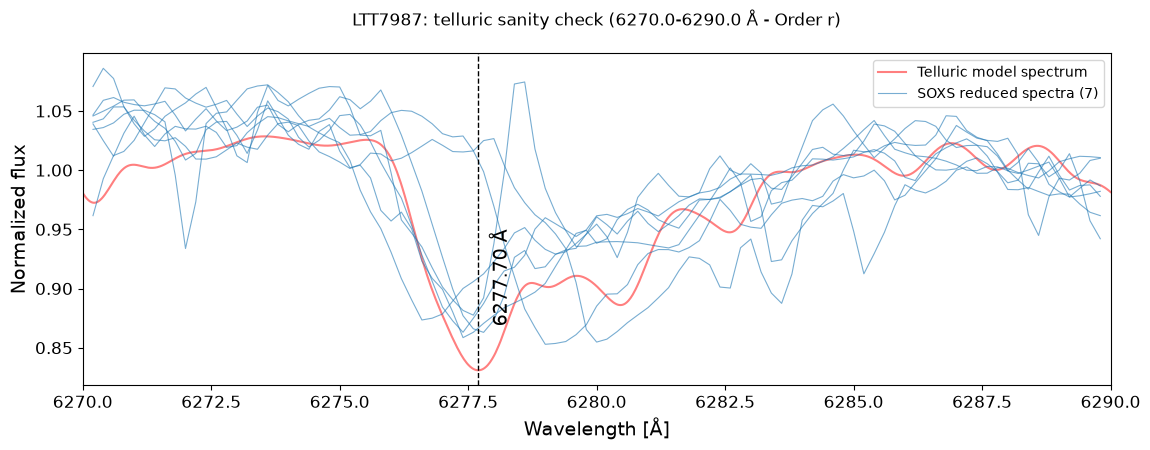

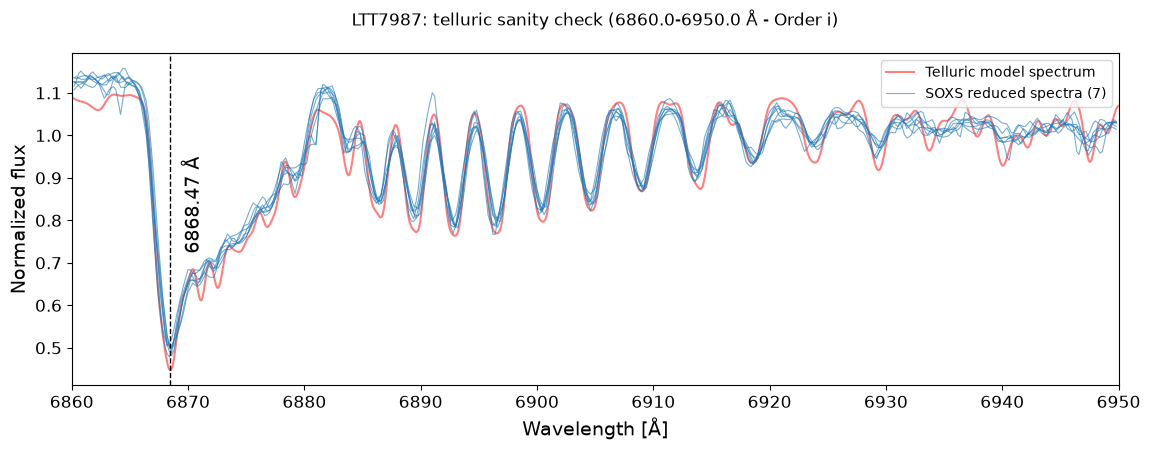

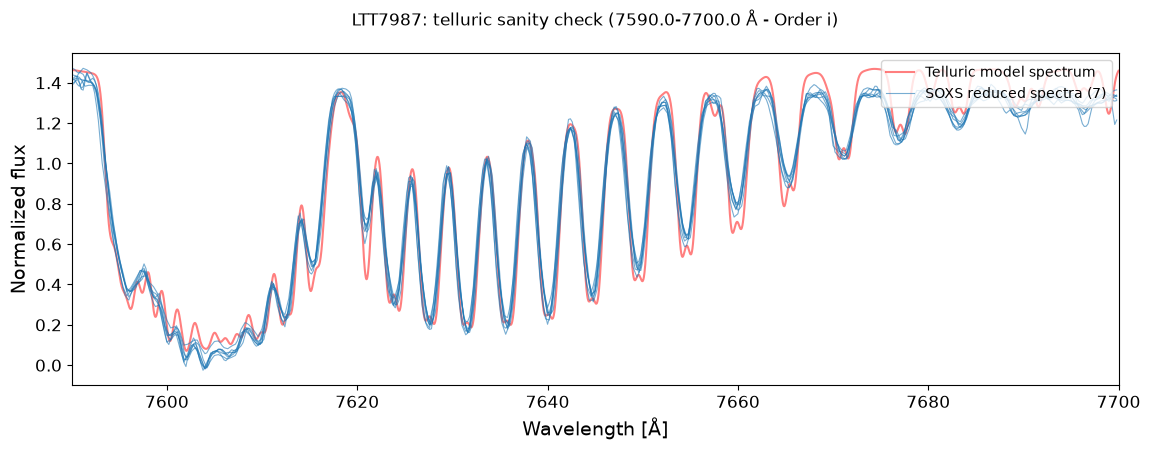

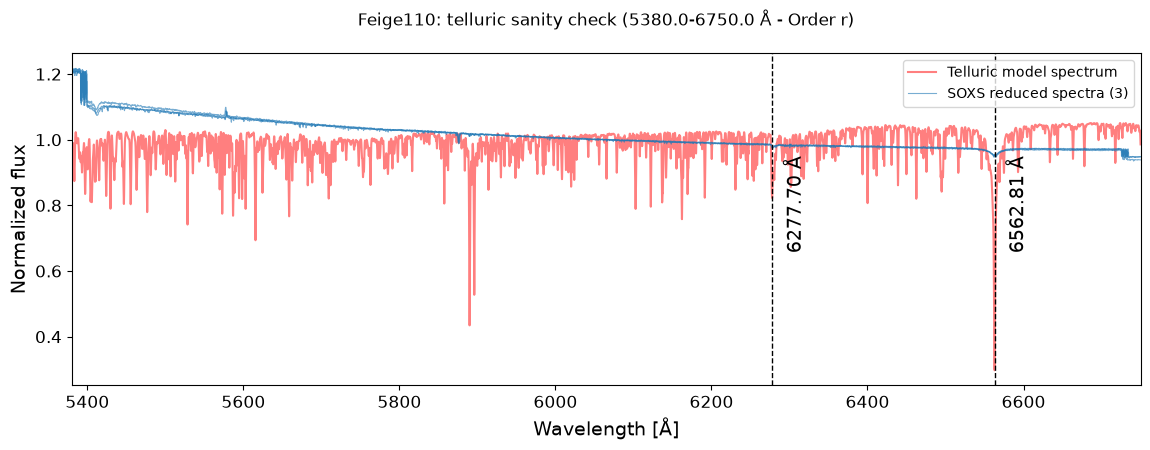

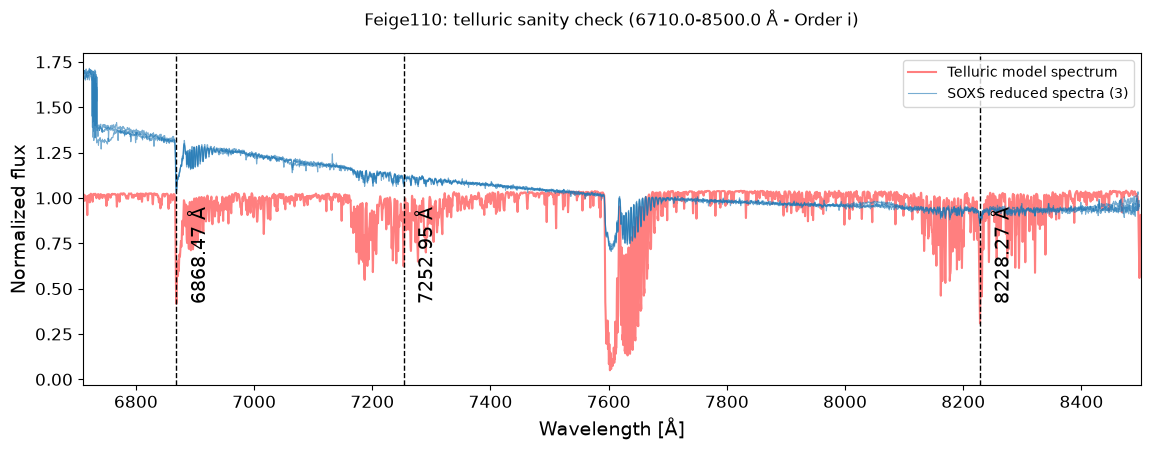

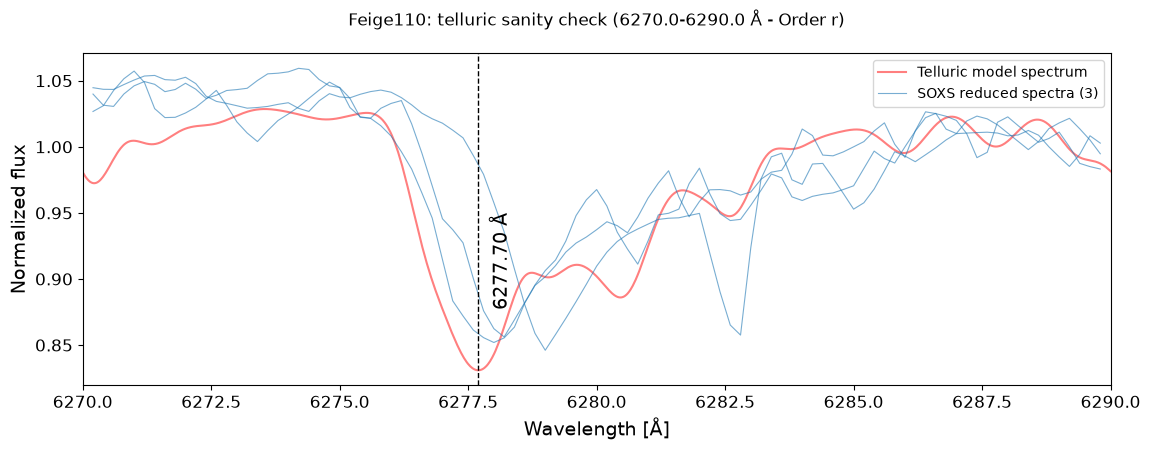

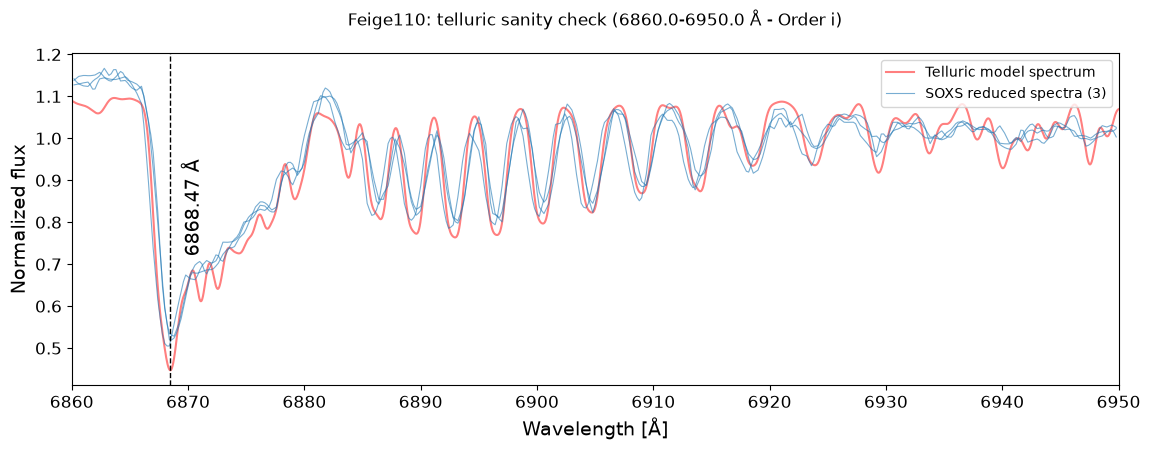

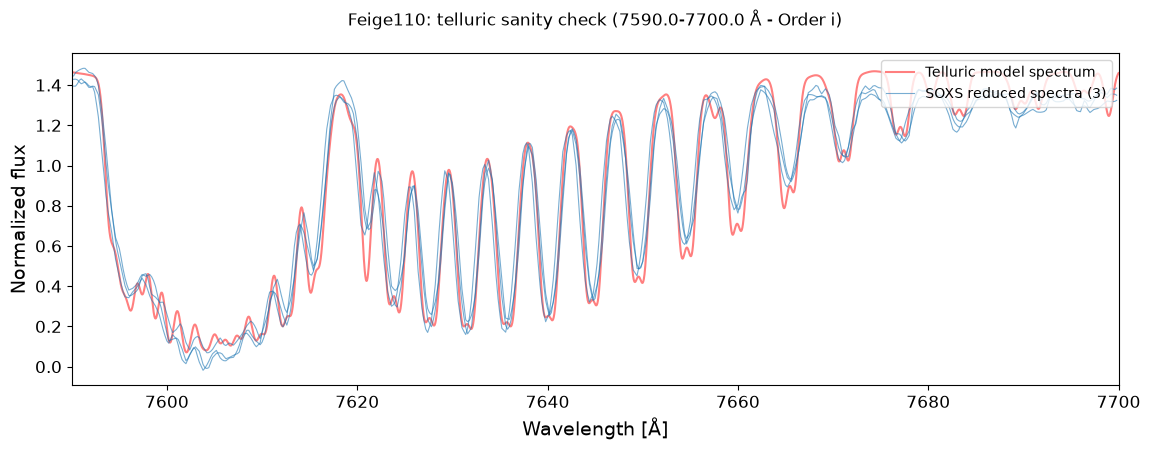

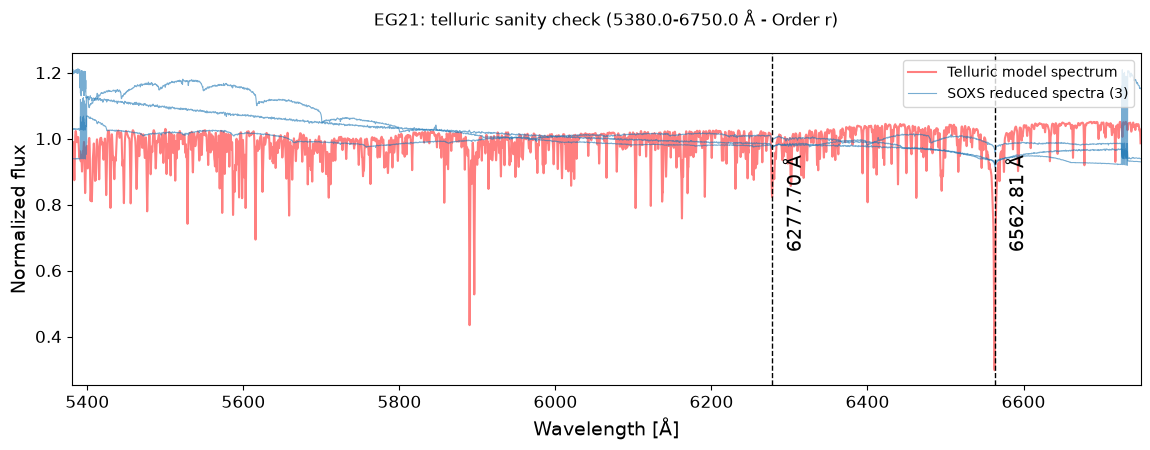

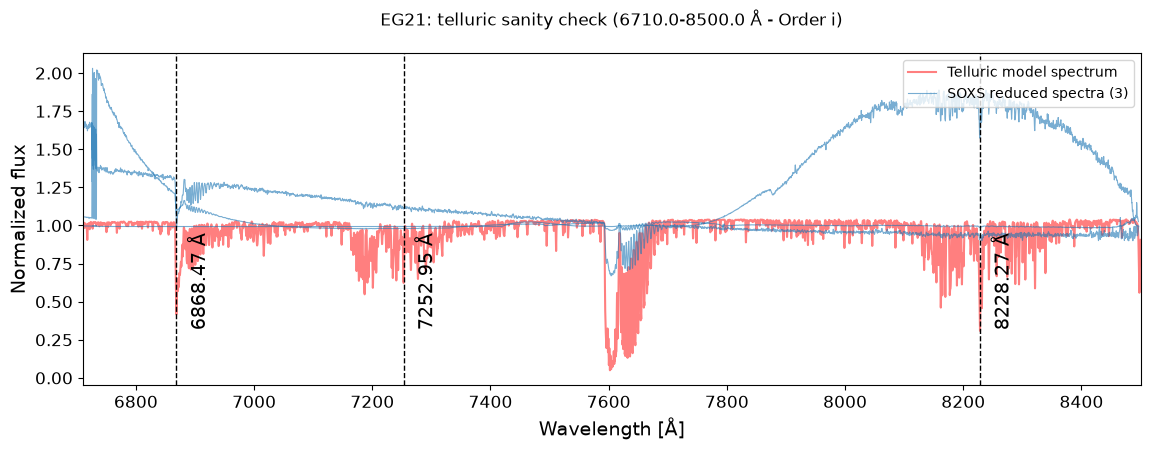

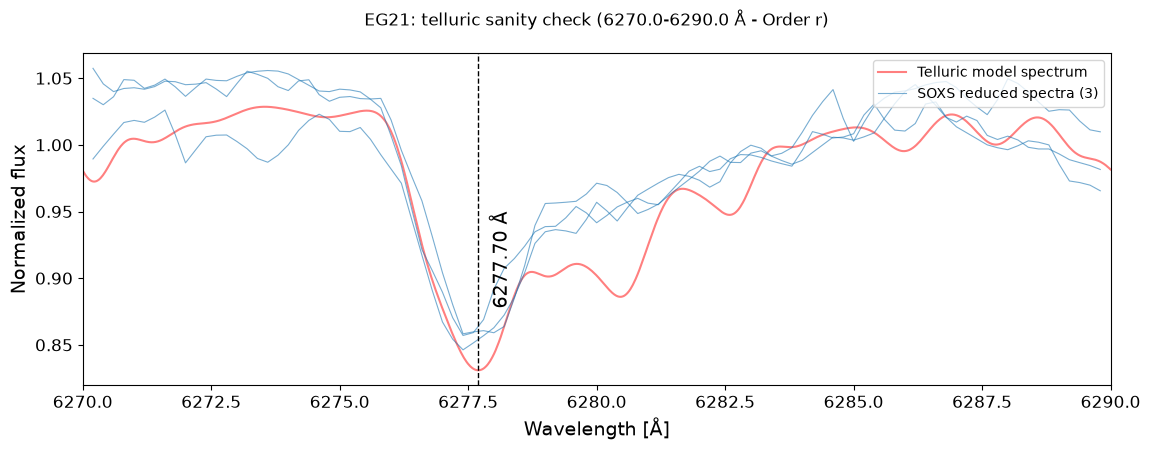

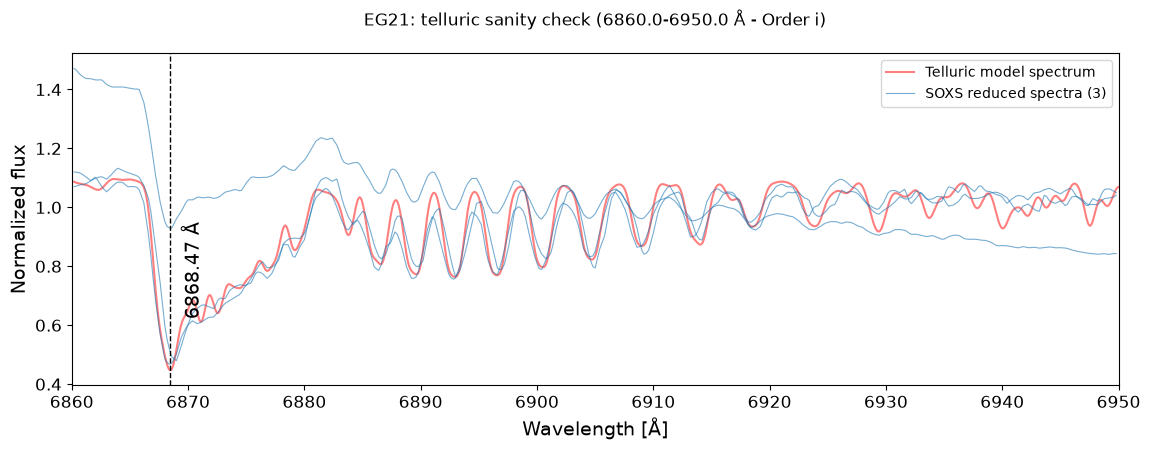

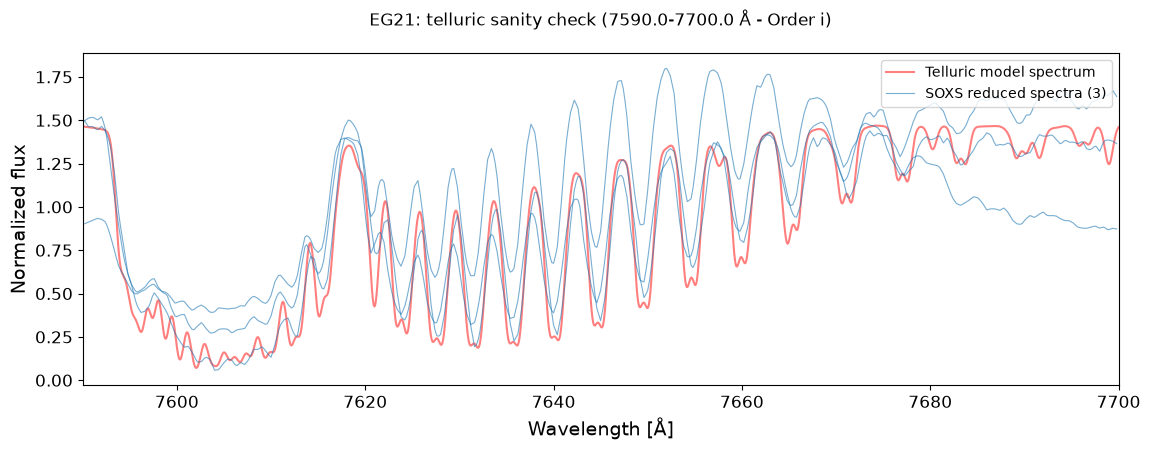

In [84]:
# DRIVER: TELLURIC SANITY-CHECK PLOTS FOR EVERY (STAR, TELLURIC WINDOW) COMBINATION
allTelluricResultRows = []

if True:

    for starName in STANDARD_STARS:
        matchedSpectra, matchedDetails = get_spectra_for_star(standardsData, details, starName)

        

        if len(matchedSpectra) == 0:
            print(f"[SKIP] no {ARM} folder spectra found for {starName}")
            continue

        for windowMin, windowMax in TELLURIC_WINDOWS:
            order = assign_spectral_order(windowMin, windowMax, spectralFormatDf)

            if ORDERS_TO_INSPECT is not None and order not in ORDERS_TO_INSPECT:
                continue

            windowTag = f"{starName}_{windowMin:.0f}-{windowMax:.0f}A"

            resultsForWindow = plot_telluric_window(
                starName, windowMin, windowMax,
                matchedSpectra, matchedDetails,
                order,
                telluricSpectrumWaveAngstrom, telluricSpectrumFlux,
                savePath=f"{PLOTS_DIR}{windowTag}_telluric.png",
            )
            allTelluricResultRows.extend(resultsForWindow)
